# FlashForge for QNX: a virtual flash chip that fails on purpose

**What you will build and see running:** a QNX 8.0 *resource manager* (`flashforged`) that appears as the device `/dev/spinor0` and behaves like a real SPI NOR flash chip, **plus a fault engine that can cut its power in the middle of a write**. A campaign cuts the power at every write of a workload, tears each write 16 different ways, and checks whether three designs of a small data store survive. A real-time demo then shows a high-priority task keeping its deadline while a slow erase runs. The notebook prints colored tables and charts for every step.

**Why it matters:** firmware in cars, medical devices and aircraft must survive power loss at any instant. Real flash hardware is slow to test and hard to break on purpose. A virtual flash that can be cut off mid-write, on command and reproducibly, lets teams find these bugs on a laptop.

**Two headline results:** (1) the same campaign finds data corruption in two plausible-looking store designs and proves a third one survives every power cut; (2) with a 45 ms erase running in the background, a plain driver makes the high-priority task miss almost every 5 ms deadline, and an erase-suspend design with QNX priority handling meets them.

### The pipeline

| Step | What happens | Output you will see |
|---|---|---|
| 0 | Preflight: internet, secrets, installer, disk | green/red requirements table |
| 1 | Install QNX Software Development Platform 8.0 | SDP table with `qcc` and `mkqnximage` paths |
| 2 | Write the nine source files | file inventory table |
| 3 | Cross-compile five programs for QNX x86_64 | build table + binary size chart |
| 4 | Build a QNX VM image, boot it in QEMU, run everything inside | boot table + serial console |
| 5 | Base device tests | test table, bit-level figure, latency chart |
| 6 | Fault-injection tests | test table + chart |
| 7 | Power-cut campaign | verdict table, outcome map, torn-write anatomy |
| 8 | Real-time demo | latency table, latency-over-time chart, deadline curve |
| 9 | Package results | scoreboard + downloadable zip |

### Before you press Run All (2 minutes, once per notebook)
1. **Settings panel (right side) > Internet: On.**
2. **Add Input > Datasets:** attach `qnx-software-center-installer`.
3. **Add-ons > Secrets:** add `QNX_USER` and `QNX_PASSWORD` (your myQNX login) and tick both for this notebook. They are never printed or saved.

### If your session expires or you refresh
Kaggle wipes the machine (including the QNX install) between sessions. **Just click Run All again.** Every cell rebuilds what it needs and skips what already exists. A full run takes roughly 10 to 20 minutes.

> **Honest scope:** QEMU emulates the CPU, so absolute timings are not hardware timings. The tear model (a prefix of the write lands, one byte lands partly, the rest does not) is a simplified but deliberately hostile model of a real power failure, and every tear is reproducible from a seed. What this notebook proves is *behaviour* on the real QNX 8.0 kernel.

## Setup
Defines paths, the secret handling, and the helpers that draw the tables. Passwords and license keys are masked in every log.

In [1]:
# =====================================================================
# SETUP - run this first in EVERY session (safe to re-run any time)
# =====================================================================
import os, re, sys, json, time, glob, html, shutil, select, hashlib, getpass, zipfile, subprocess, urllib.request
from pathlib import Path
from IPython.display import HTML, display

PROJECT  = Path("/kaggle/working/qnx-flashforge")   # sources + results (kept when you Save Version)
RESULTS  = PROJECT / "results"
LOGS     = RESULTS / "logs"
FIGS     = RESULTS / "figures"
SDP      = Path("/root/qnx800_flashforge")          # /root is wiped by Kaggle between sessions
SDP_ENV  = SDP / "qnxsdp-env.sh"
PKG_DIR  = Path("/root/qnx_sc_pkg")
IMG_DIR  = Path("/root/ff_qemu_image")
BASELINE = "com.qnx.qnx800"
INSTALLER_SHA256 = "5695a0ec8a1fd91840753b2cba86a9325f6052d4f69c757166cc61b09bcbe507"
_hits = sorted(glob.glob("/kaggle/input/**/qnx-setup-*-linux.run", recursive=True))
INSTALLER = Path(_hits[0]) if _hits else None
for _d in (PROJECT, RESULTS, LOGS, FIGS):
    _d.mkdir(parents=True, exist_ok=True)

def get_secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name) or None
    except Exception:
        return None

QNX_USER = get_secret("QNX_USER")
QNX_PASS = get_secret("QNX_PASSWORD")

KEY_RE = re.compile(r"\b[A-Z0-9]{4}(?:-[A-Z0-9]{4}){4}\b")
def scrub(text):
    """Mask secrets and license keys before anything is printed or logged."""
    text = KEY_RE.sub("XXXX-XXXX-XXXX-XXXX-XXXX", str(text))
    text = re.sub(r"(-myqnx\.password=)\S+", r"\1***", text)
    text = re.sub(r"(-myqnx\.user=)\S+", r"\1<user>", text)
    for secret, mask in ((QNX_PASS, "***"), (QNX_USER, "<user>")):
        if secret:
            text = text.replace(secret, mask)
    return text

def sh(cmd, timeout=120):
    r = subprocess.run(["bash", "-lc", cmd], capture_output=True, text=True, timeout=timeout)
    return r.returncode, (r.stdout or "") + (r.stderr or "")

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def run_logged(cmd, timeout, label, logfile):
    """Run a command (no shell), stream masked output to a log, print a heartbeat."""
    start = last = time.time()
    tail = []
    with open(logfile, "a", encoding="utf-8") as lf:
        lf.write("\n$ " + scrub(label) + "\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, bufsize=1, env=dict(os.environ))
        while True:
            if time.time() - start > timeout:
                p.kill(); lf.write("[timeout]\n")
                return -9, tail
            ready, _, _ = select.select([p.stdout], [], [], 5)
            if ready:
                raw = p.stdout.readline()
                if raw == "":
                    break
                line = scrub(raw.rstrip("\n"))
                lf.write(line + "\n"); lf.flush()
                tail = (tail + [line])[-12:]
                if time.time() - last >= 30:
                    print(f"[{int(time.time()-start):>5}s] {line[:110]}"); last = time.time()
            else:
                if p.poll() is not None:
                    break
                if time.time() - last >= 60:
                    print(f"[{int(time.time()-start):>5}s] still running ..."); last = time.time()
        return p.wait(), tail

# ---------- pretty output helpers (tables with colored status) ----------
COLORS = {"PASS": "#1a7f37", "WARN": "#9a6700", "FAIL": "#cf222e", "INFO": "#57606a"}
ICONS  = {"PASS": "&#9989;", "WARN": "&#9888;&#65039;", "FAIL": "&#10060;", "INFO": "&#8505;&#65039;"}

def html_table(headers, rows, status_col=None, mono_cols=()):
    th = "".join(f"<th style='padding:6px 10px;text-align:left'>{html.escape(str(h))}</th>" for h in headers)
    body = ""
    for r in rows:
        tds = ""
        for i, v in enumerate(r):
            s = html.escape(str(v))
            style = "padding:6px 10px;border-top:1px solid #eaeef2;vertical-align:top;"
            if i == status_col and str(v) in COLORS:
                style += f"color:{COLORS[str(v)]};font-weight:700;white-space:nowrap;"
                s = f"{ICONS[str(v)]} {s}"
            if i in mono_cols:
                style += "font-family:monospace;font-size:12px;"
            tds += f"<td style='{style}'>{s}</td>"
        body += f"<tr>{tds}</tr>"
    return ("<table style='border-collapse:collapse;width:100%;border:1px solid #d0d7de;"
            "font-family:sans-serif;font-size:14px;color:#24292f;background:#fff'>"
            f"<tr style='background:#f6f8fa'>{th}</tr>{body}</table>")

def banner(text, ok=True, sub=""):
    color = COLORS["PASS"] if ok else COLORS["FAIL"]
    extra = f"<div style='font-weight:400;font-size:13px;margin-top:4px'>{html.escape(sub)}</div>" if sub else ""
    display(HTML(f"<div style='font-family:sans-serif;background:{color};color:#fff;padding:12px 16px;"
                 f"border-radius:6px;font-weight:700;font-size:16px'>{html.escape(text)}{extra}</div>"))

SCORE = {}
class Phase:
    """Collects checks, shows one colored table, records the result, stops the notebook on failure."""
    def __init__(self, key, title, ok_text, bad_text):
        self.key, self.title, self.ok_text, self.bad_text = key, title, ok_text, bad_text
        self.rows = []
    def add(self, check, status, detail=""):
        self.rows.append((check, status, scrub(detail)[:400]))
    def finish(self, stop=True):
        failed = any(s == "FAIL" for _, s, _ in self.rows)
        color = COLORS["FAIL"] if failed else COLORS["PASS"]
        text = self.bad_text if failed else self.ok_text
        rows = [(i, c, s, d) for i, (c, s, d) in enumerate(self.rows, 1)]
        display(HTML("<div style='font-family:sans-serif'>"
                     f"<div style='background:{color};color:#fff;padding:10px 14px;border-radius:6px 6px 0 0;"
                     f"font-weight:700'>{html.escape(self.title)}: {html.escape(text)}</div>"
                     + html_table(["#", "Check", "Status", "Detail"], rows, status_col=2, mono_cols=(3,)) + "</div>"))
        SCORE[self.key] = {"title": self.title, "status": "FAIL" if failed else "PASS",
                           "checks": [{"check": c, "status": s, "detail": d} for c, s, d in self.rows]}
        (RESULTS / "scoreboard.json").write_text(json.dumps(SCORE, indent=2))
        if failed and stop:
            raise RuntimeError(f"{self.title} failed - read the red rows above, fix them, then re-run this cell.")
        return not failed

print("Setup complete. Project folder:", PROJECT)


Setup complete. Project folder: /kaggle/working/qnx-flashforge


## Step 0: Preflight
Checks every requirement *before* spending time. A red row tells you exactly what to fix; the notebook stops there instead of failing later with a confusing error.

In [2]:
# Step 0 - Preflight: check everything the notebook needs BEFORE spending time on it
import platform
p = Phase("00_preflight", "Preflight", "READY - all requirements met", "NOT READY - fix the red rows")

p.add("Python / OS", "INFO", f"Python {platform.python_version()} on {platform.platform()}")

try:
    urllib.request.urlopen("https://www.qnx.com", timeout=15).close()
    p.add("Internet reachable (qnx.com)", "PASS", "ok")
except Exception as exc:
    p.add("Internet reachable (qnx.com)", "FAIL",
          f"{type(exc).__name__}. Open the right-hand Settings panel and turn Internet ON, then re-run.")

if QNX_USER and QNX_PASS:
    p.add("Kaggle Secrets QNX_USER / QNX_PASSWORD", "PASS", "both present (values never printed)")
else:
    p.add("Kaggle Secrets QNX_USER / QNX_PASSWORD", "WARN",
          "missing or switched off. Add-ons > Secrets: add both and tick them for this notebook "
          "(otherwise Step 1 will ask you to type them).")

if INSTALLER and INSTALLER.is_file():
    actual = sha256(INSTALLER)
    good = actual == INSTALLER_SHA256
    p.add("QNX Software Center installer dataset", "PASS" if good else "FAIL",
          f"{INSTALLER.name}; sha256 {actual[:16]}... {'matches' if good else 'DOES NOT MATCH'}")
else:
    p.add("QNX Software Center installer dataset", "FAIL",
          "not found. Add Input > Datasets > qnx-software-center-installer, then re-run.")

os.makedirs("/root", exist_ok=True)
free_gb = shutil.disk_usage("/root").free / 1e9
p.add("Free disk on /root", "PASS" if free_gb >= 15 else "FAIL", f"{free_gb:.0f} GB free (need about 15 GB)")

mem_gb = None
try:
    mem_gb = int(re.search(r"MemTotal:\s+(\d+)", open("/proc/meminfo").read()).group(1)) / 1e6
except Exception:
    pass
p.add("CPU / RAM", "INFO", f"{os.cpu_count()} cores, {mem_gb:.1f} GB RAM" if mem_gb else f"{os.cpu_count()} cores")

kvm = os.access("/dev/kvm", os.R_OK | os.W_OK)
p.add("KVM acceleration", "PASS" if kvm else "INFO",
      "available - QNX will boot fast" if kvm else "not available - QEMU uses software emulation (slower, still works)")

p.add("QEMU installed", "INFO", shutil.which("qemu-system-x86_64") or "not yet - Step 4a installs it")
p.finish()


#,Check,Status,Detail
1,Python / OS,ℹ️ INFO,Python 3.13.18 on Linux-6.18.55+-x86_64-with-glibc2.39
2,Internet reachable (qnx.com),✅ PASS,ok
3,Kaggle Secrets QNX_USER / QNX_PASSWORD,✅ PASS,both present (values never printed)
4,QNX Software Center installer dataset,✅ PASS,qnx-setup-2.0.4-202501021438-linux.run; sha256 5695a0ec8a1fd918... matches
5,Free disk on /root,✅ PASS,1038 GB free (need about 15 GB)
6,CPU / RAM,ℹ️ INFO,"4 cores, 32.9 GB RAM"
7,KVM acceleration,ℹ️ INFO,"not available - QEMU uses software emulation (slower, still works)"
8,QEMU installed,ℹ️ INFO,not yet - Step 4a installs it


True

## Step 1: Install the QNX SDP 8.0
The **QNX Software Development Platform (SDP)** contains the compiler (`qcc`), the OS libraries, and `mkqnximage`, the tool that builds a bootable QNX virtual machine.

The installer is a self-extracting archive. We unpack it, then use the Software Center command-line tool with your myQNX login to **mirror** (download) and install baseline `com.qnx.qnx800`. If QNX says the license key is not activated on this machine (every Kaggle session is a new machine), the cell activates it automatically and retries. It takes one to three minutes and skips itself if QNX is already installed in this session.

In [3]:
# Step 1 - Install QNX SDP 8.0 (about 2 minutes). Skips itself if the SDP is already there.
p = Phase("01_sdp", "QNX SDP 8.0", "QNX SDP READY", "SDP INSTALL FAILED")
LOG1 = LOGS / "step1_sdp_install.log"

def verify_sdp():
    rc, out = sh(f"source '{SDP_ENV}' && which qcc && which mkqnximage && which mkifs && qcc -V 2>&1 | head -60", 180)
    return (rc == 0 and "gcc_ntox86_64" in out), out

sdp_ok = False
if SDP_ENV.is_file():
    sdp_ok, out = verify_sdp()
    p.add("SDP already installed", "PASS" if sdp_ok else "WARN",
          "found in this session - skipping install" if sdp_ok else "present but not usable - reinstalling")

if not sdp_ok:
    if not (QNX_USER and QNX_PASS):
        print("Kaggle Secrets not found. Type your myQNX login (hidden, never saved in the notebook):")
        QNX_USER = getpass.getpass("myQNX email: ").strip()
        QNX_PASS = getpass.getpass("myQNX password: ")
    if not (QNX_USER and QNX_PASS):
        p.add("myQNX credentials", "FAIL", "nothing entered")
        p.finish()
    p.add("myQNX credentials", "PASS", "provided (values never printed)")

    if PKG_DIR.exists():
        shutil.rmtree(PKG_DIR)
    rc, tail = run_logged(["bash", str(INSTALLER), "--noexec", "--target", str(PKG_DIR)], 300,
                          "installer --noexec --target " + str(PKG_DIR), LOG1)
    clts = [c for c in sorted(PKG_DIR.rglob("qnxsoftwarecenter_clt*")) if c.is_file()]
    if rc != 0 or not clts:
        p.add("Unpack Software Center", "FAIL", f"exit {rc}; " + " | ".join(tail[-3:]))
        p.finish()
    clt = clts[0]
    clt.chmod(0o755)
    p.add("Unpack Software Center", "PASS", f"command-line tool: {clt.relative_to(PKG_DIR)}")

    creds = [f"-myqnx.user={QNX_USER}", f"-myqnx.password={QNX_PASS}"]

    def attempt_install():
        # A fresh Kaggle session has an empty QNX download cache, so mirror (download) the baseline first.
        cmd = [str(clt), *creds, "-cleanInstall", "-mirrorBaseline", "qnx800",
               "-installBaseline", BASELINE, "-destination", str(SDP)]
        print(f"Downloading and installing {BASELINE} into {SDP} ... (1 to 3 minutes)")
        t0 = time.time()
        rc, tail = run_logged(cmd, 3600, f"{clt.name} ... -cleanInstall -mirrorBaseline qnx800 "
                                         f"-installBaseline {BASELINE} -destination {SDP}", LOG1)
        return rc, tail, int(time.time() - t0)

    def activate_license():
        # Every Kaggle session is a new machine, so the key in your myQNX account must be activated on it.
        # Optional Kaggle Secret QNX_LICENSE_KEY is used only if the account sync does not find a key.
        extra = []
        key = get_secret("QNX_LICENSE_KEY")
        if key:
            extra = ["-addLicenseKey", key.strip()]
        cmd = [str(clt), *creds, "-syncLicenseKeys", *extra, "-activateAll", "-listLicenseKeys"]
        return run_logged(cmd, 600, f"{clt.name} ... -syncLicenseKeys -activateAll -listLicenseKeys", LOG1)

    rc, tail, secs = attempt_install()
    if rc != 0 and any("license" in l.lower() for l in tail):
        print("The QNX license key is not activated on this machine yet - activating it now ...")
        arc, atail = activate_license()
        p.add("Activate QNX license on this machine", "PASS" if arc == 0 else "FAIL",
              "activated" if arc == 0 else f"exit {arc}: " + " | ".join(atail[-4:]))
        if arc != 0:
            p.finish()
        rc, tail, secs = attempt_install()
    if rc != 0 or not SDP_ENV.is_file():
        hint = (" | still a license problem: add Kaggle Secret QNX_LICENSE_KEY (your QNX 8.0 key) and re-run"
                if any("icense" in l for l in tail) else "")
        p.add("Install QNX SDP 8.0", "FAIL", f"exit {rc} after {secs}s: " + " | ".join(tail[-4:]) + hint)
        p.finish()
    p.add("Install QNX SDP 8.0", "PASS", f"{secs} s")
    sdp_ok, out = verify_sdp()

paths = [l.strip() for l in out.splitlines() if l.strip().startswith("/")]
p.add("qcc compiler", "PASS" if paths else "FAIL", paths[0] if paths else out[-200:])
p.add("x86_64 target variant (gcc_ntox86_64)", "PASS" if "gcc_ntox86_64" in out else "FAIL", "listed by qcc -V")
p.add("mkqnximage (VM image builder)", "PASS" if any("mkqnximage" in x for x in paths) else "FAIL",
      next((x for x in paths if "mkqnximage" in x), "not found"))
p.finish()


The QNX license key is not activated on this machine yet - activating it now ...
[   64s] still running ...
[  124s] still running ...


#,Check,Status,Detail
1,myQNX credentials,✅ PASS,provided (values never printed)
2,Unpack Software Center,✅ PASS,command-line tool: qnxsoftwarecenter/qnxsoftwarecenter_clt
3,Activate QNX license on this machine,✅ PASS,activated
4,Install QNX SDP 8.0,✅ PASS,144 s
5,qcc compiler,✅ PASS,/root/qnx800_flashforge/host/linux/x86_64/usr/bin/qcc
6,x86_64 target variant (gcc_ntox86_64),✅ PASS,listed by qcc -V
7,mkqnximage (VM image builder),✅ PASS,/root/qnx800_flashforge/host/common/bin/mkqnximage


True

## Step 2: The source code (nine files)

### Background you need for the code

**NOR flash rules.** A NOR flash chip has two operations that matter:
- **Erase** works on a whole *sector* (4096 bytes) and sets every bit to `1` (byte `0xFF`).
- **Program** writes data, one *page* (256 bytes) at a time, but can only change bits from `1` to `0`. Programming `0xF0` and then `0x3C` over the same byte leaves `0x30` (a bitwise AND). Getting a `1` back requires erasing the whole sector.

**What a power cut does.** If power fails during a program, a prefix of the bytes is written, one byte may be written only partly (some bits cleared, some not), and the rest is untouched. If it fails during an erase, a prefix of the sector is erased and the rest keeps its old data. Software that restarts afterwards sees this half-written state. Nothing in the flash tells it the write was interrupted.

**QNX resource manager.** QNX is a microkernel: drivers are normal user-space programs. A *resource manager* registers a name in the filesystem (`/dev/spinor0`). When a program calls `open`, `read`, `write` or `devctl` on that name, QNX turns the call into a **message** for the resource manager, which replies. A driver bug cannot crash the OS.

**`devctl`.** Reads and writes carry data; `devctl` carries *commands*. FlashForge has eleven: geometry, erase, statistics, reset, timing, and the fault controls below.

| `devctl` command | What it does |
|---|---|
| `POWER_CUT` | Let N more operations finish, then tear the next one and switch the chip off |
| `POWER_RESTORE` | Switch the chip back on; whatever is in the flash stays |
| `STUCK_BIT` | Force one bit to read as 0 or 1, like a failed cell |
| `FLIP_BIT` | Flip one stored bit, like bit rot |
| `WEAR_LIMIT` | Make every sector stop erasing after N erases |
| `STATS` | Operation counters, power state, and what the last operation was |
| `RESET_ALL` | Factory-fresh chip: all `0xFF`, counters zero, faults cleared |
| `TIMING` | Make erase take real time (45 ms) and choose how it treats waiting reads |

**The three store designs.** The campaign tests a tiny append-only record store, 32 bytes per record. All three designs write identical bytes; they differ only in how they recover after a crash:

| Design | Rule after a restart | Expected weakness |
|---|---|---|
| **A** naive | a record is valid if its first field is not erased | accepts half-written garbage |
| **B** CRC, reuses torn slot | a record is valid if its CRC matches; the first bad slot is where new records go | a new record is written on top of a half-written one, which can never produce a valid record |
| **C** CRC, skips torn slots | valid if CRC matches; half-written slots are skipped; new records go to the first fully erased slot | none |

| File | Role |
|---|---|
| `include/ff_ioctl.h` | Shared constants: device name, geometry, `devctl` commands and their structs |
| `src/ff_core.h` | The NOR model and the fault engine, in plain C with no QNX dependency |
| `src/ff_chip.h` | Thread-safe chip with simulated timing: priority-inheriting lock, blocking erase, erase-suspend |
| `src/flashforged.c` | The multithreaded QNX driver: connects `/dev/spinor0` to the chip |
| `tests/ff_test.c` | 15 base conformance tests plus timing |
| `tests/ff_fault_test.c` | 16 tests proving every fault command works |
| `tests/ff_campaign.c` | The power-cut campaign over the three store designs |
| `tests/ff_rt_demo.c` | The real-time demo: deadline-driven reader against a background eraser |
| `build.sh` | Compiles all five programs for QNX x86_64 |

> The files in your GitHub repo are older than these. Copy the new versions across after this run passes.

In [4]:
# Create the project folders (the next four cells write the source files into them)
for sub in ("src", "include", "tests", "docs"):
    (PROJECT / sub).mkdir(parents=True, exist_ok=True)
print("Folders ready under", PROJECT)


Folders ready under /kaggle/working/qnx-flashforge


### File 1 of 9: `build.sh`

In [5]:
%%writefile /kaggle/working/qnx-flashforge/build.sh
#!/bin/sh
# Run after sourcing qnxsdp-env.sh from your QNX SDP 8.0 install
set -e
mkdir -p build
qcc -Vgcc_ntox86_64 -Wall -O2 -Iinclude -Isrc -o build/flashforged src/flashforged.c
qcc -Vgcc_ntox86_64 -Wall -O2 -Iinclude -o build/ff_test tests/ff_test.c
qcc -Vgcc_ntox86_64 -Wall -O2 -Iinclude -o build/ff_fault_test tests/ff_fault_test.c
qcc -Vgcc_ntox86_64 -Wall -O2 -Iinclude -o build/ff_campaign tests/ff_campaign.c
qcc -Vgcc_ntox86_64 -Wall -O2 -Iinclude -o build/ff_rt_demo tests/ff_rt_demo.c
echo "built: flashforged ff_test ff_fault_test ff_campaign ff_rt_demo"


Writing /kaggle/working/qnx-flashforge/build.sh


### File 2 of 9: `include/ff_ioctl.h`
The contract between driver and clients. `__DIOF` marks a command that returns data, `__DIOT` one that sends data, `__DION` one with no data.

In [6]:
%%writefile /kaggle/working/qnx-flashforge/include/ff_ioctl.h
#ifndef FF_IOCTL_H
#define FF_IOCTL_H

#include <stdint.h>
#include <devctl.h>

#ifndef _DCMD_MISC
#define _DCMD_MISC 0x0c
#endif

#define FF_DEV_PATH "/dev/spinor0"

#define FF_FLASH_BYTES  1048576u
#define FF_SECTOR_BYTES 4096u
#define FF_PAGE_BYTES   256u
#define FF_SECTORS      (FF_FLASH_BYTES / FF_SECTOR_BYTES)

#define FF_OP_NONE    0u
#define FF_OP_PROGRAM 1u
#define FF_OP_ERASE   2u

typedef struct {
    uint32_t total_bytes;
    uint32_t sector_bytes;
    uint32_t page_bytes;
    uint32_t sector_count;
} ff_geometry_t;

typedef struct { uint32_t sector; } ff_erase_t;

/* after_ops = number of program/erase operations allowed to finish; the next one is torn. */
typedef struct { uint32_t after_ops; uint32_t seed; } ff_powercut_t;
typedef struct { uint32_t offset; uint32_t bit; uint32_t value; } ff_stuck_t;
typedef struct { uint32_t offset; uint32_t bit; } ff_flip_t;
typedef struct { uint32_t limit; } ff_wear_t;

/* Simulated chip timing. mode 0 = instant, 1 = erase blocks the chip for erase_us,
 * 2 = erase is suspended at every slice_us boundary while a read is waiting. */
#define FF_TIMING_INSTANT  0u
#define FF_TIMING_BLOCKING 1u
#define FF_TIMING_SUSPEND  2u
typedef struct { uint32_t mode; uint32_t erase_us; uint32_t slice_us; uint32_t reserved; } ff_timing_t;

typedef struct {
    uint64_t op_count;
    uint64_t reads;
    uint64_t programs;
    uint64_t erases;
    uint64_t torn_ops;
    uint32_t power_lost;
    uint32_t wear_limit;
    uint32_t stuck_count;
    uint32_t max_erase_count;
    uint32_t last_op_kind;
    uint32_t last_op_offset;
    uint32_t last_op_len;
    uint32_t peak_handlers;   /* most requests the driver has had in flight at once */
    uint32_t distinct_threads;/* how many different server threads have handled requests */
    uint32_t pad2;
} ff_stats_t;

#define FF_DCMD_GEOMETRY      __DIOF(_DCMD_MISC, 0x100, ff_geometry_t)
#define FF_DCMD_ERASE         __DIOT(_DCMD_MISC, 0x101, ff_erase_t)
#define FF_DCMD_STATS         __DIOF(_DCMD_MISC, 0x102, ff_stats_t)
#define FF_DCMD_RESET_ALL     __DION(_DCMD_MISC, 0x103)
#define FF_DCMD_FAULT_CLEAR   __DION(_DCMD_MISC, 0x104)
#define FF_DCMD_POWER_CUT     __DIOT(_DCMD_MISC, 0x105, ff_powercut_t)
#define FF_DCMD_POWER_RESTORE __DION(_DCMD_MISC, 0x106)
#define FF_DCMD_STUCK_BIT     __DIOT(_DCMD_MISC, 0x107, ff_stuck_t)
#define FF_DCMD_FLIP_BIT      __DIOT(_DCMD_MISC, 0x108, ff_flip_t)
#define FF_DCMD_WEAR_LIMIT    __DIOT(_DCMD_MISC, 0x109, ff_wear_t)
#define FF_DCMD_TIMING        __DIOT(_DCMD_MISC, 0x10A, ff_timing_t)

#endif


Writing /kaggle/working/qnx-flashforge/include/ff_ioctl.h


### File 3 of 9: `src/ff_core.h` (the fault engine)
Read these functions:
- `ff_core_program` splits every write at page boundaries; **each page is one operation**, and the operation counter is what a power cut is aimed at.
- `ff_core_begin_op` decides whether this operation is the one that gets torn.
- `ff_tear_program` and `ff_tear_erase` produce the half-written state. Their pseudo-random choices come from a seed, so every tear can be replayed exactly.

In [7]:
%%writefile /kaggle/working/qnx-flashforge/src/ff_core.h
/* ff_core.h - NOR flash model and fault engine.
 * Pure C with no QNX dependencies, so the same code runs inside the QNX
 * resource manager and in host-side tests. */
#ifndef FF_CORE_H
#define FF_CORE_H

#include <stdint.h>
#include <string.h>
#include <errno.h>
#include "ff_ioctl.h"

#define FF_MAX_STUCK 16

typedef struct {
    uint32_t offset;
    uint8_t  bit;
    uint8_t  value;
} ff_stuck_cell_t;

typedef struct {
    uint8_t         mem[FF_FLASH_BYTES];
    uint32_t        erase_count[FF_SECTORS];
    uint32_t        wear_limit;      /* 0 = unlimited */
    uint64_t        op_count;        /* program (per page) + erase operations since reset */
    uint64_t        reads, programs, erases, torn_ops;
    int             cut_armed;
    uint32_t        cut_remaining;   /* operations still allowed to finish before the tear */
    uint32_t        cut_seed;
    int             power_lost;
    uint32_t        stuck_n;
    ff_stuck_cell_t stuck[FF_MAX_STUCK];
    uint32_t        last_kind, last_off, last_len;
} ff_core_t;

static uint32_t ff_rng(uint32_t *s)
{
    uint32_t x = *s;
    x ^= x << 13; x ^= x >> 17; x ^= x << 5;
    *s = x;
    return x;
}

static void ff_core_reset(ff_core_t *c)
{
    memset(c->mem, 0xFF, sizeof(c->mem));
    memset(c->erase_count, 0, sizeof(c->erase_count));
    c->wear_limit = 0;
    c->op_count = c->reads = c->programs = c->erases = c->torn_ops = 0;
    c->cut_armed = 0; c->cut_remaining = 0; c->cut_seed = 0;
    c->power_lost = 0;
    c->stuck_n = 0;
    c->last_kind = FF_OP_NONE; c->last_off = 0; c->last_len = 0;
}

static void ff_core_fault_clear(ff_core_t *c)
{
    c->wear_limit = 0;
    c->cut_armed = 0;
    c->stuck_n = 0;
}

static void ff_core_power_cut(ff_core_t *c, uint32_t after_ops, uint32_t seed)
{
    c->cut_armed = 1;
    c->cut_remaining = after_ops;
    c->cut_seed = seed;
}

static void ff_core_power_restore(ff_core_t *c)
{
    c->power_lost = 0;
    c->cut_armed = 0;
}

static int ff_core_stuck(ff_core_t *c, uint32_t off, uint32_t bit, uint32_t value)
{
    if (off >= FF_FLASH_BYTES || bit > 7) return EINVAL;
    if (c->stuck_n >= FF_MAX_STUCK) return ENOSPC;
    c->stuck[c->stuck_n].offset = off;
    c->stuck[c->stuck_n].bit = (uint8_t)bit;
    c->stuck[c->stuck_n].value = (uint8_t)(value ? 1 : 0);
    c->stuck_n++;
    return 0;
}

static int ff_core_flip(ff_core_t *c, uint32_t off, uint32_t bit)
{
    if (off >= FF_FLASH_BYTES || bit > 7) return EINVAL;
    c->mem[off] ^= (uint8_t)(1u << bit);
    return 0;
}

/* Returns 0 and sets *tear when this operation must be cut short; EIO when the power is already off. */
static int ff_core_begin_op(ff_core_t *c, uint32_t kind, uint32_t off, uint32_t len, int *tear)
{
    *tear = 0;
    if (c->power_lost) return EIO;
    c->op_count++;
    c->last_kind = kind; c->last_off = off; c->last_len = len;
    if (c->cut_armed) {
        if (c->cut_remaining == 0) {
            *tear = 1;
            c->torn_ops++;
            c->power_lost = 1;
            c->cut_armed = 0;
        } else {
            c->cut_remaining--;
        }
    }
    return 0;
}

static uint32_t ff_tear_seed(const ff_core_t *c)
{
    uint32_t s = c->cut_seed * 2654435761u ^ (uint32_t)c->op_count * 40503u ^ 0x9E3779B9u;
    return s ? s : 1u;
}

/* Power failed during a page program: a prefix was programmed, one byte only partly, the rest untouched. */
static void ff_tear_program(ff_core_t *c, uint32_t off, const uint8_t *d, uint32_t n)
{
    uint32_t s = ff_tear_seed(c);
    uint32_t k = ff_rng(&s) % n;
    uint8_t rnd = (uint8_t)ff_rng(&s);
    uint32_t i;
    for (i = 0; i < k; i++) c->mem[off + i] &= d[i];
    c->mem[off + k] &= (uint8_t)(d[k] | rnd);
}

/* Power failed during a sector erase: a prefix is erased, one byte only partly, the rest keeps old data. */
static void ff_tear_erase(ff_core_t *c, uint32_t sector)
{
    uint32_t s = ff_tear_seed(c);
    uint32_t base = sector * FF_SECTOR_BYTES;
    uint32_t k = ff_rng(&s) % FF_SECTOR_BYTES;
    uint8_t rnd = (uint8_t)ff_rng(&s);
    memset(c->mem + base, 0xFF, k);
    c->mem[base + k] |= rnd;
}

static int ff_core_erase(ff_core_t *c, uint32_t sector)
{
    int tear, rc;
    if (sector >= FF_SECTORS) return EINVAL;
    rc = ff_core_begin_op(c, FF_OP_ERASE, sector * FF_SECTOR_BYTES, FF_SECTOR_BYTES, &tear);
    if (rc) return rc;
    if (tear) { ff_tear_erase(c, sector); return EIO; }
    if (c->wear_limit && c->erase_count[sector] >= c->wear_limit) return EIO; /* worn out: erase has no effect */
    memset(c->mem + (size_t)sector * FF_SECTOR_BYTES, 0xFF, FF_SECTOR_BYTES);
    c->erase_count[sector]++;
    c->erases++;
    return 0;
}

/* Programs n bytes; the span is split at page boundaries and every page is one operation. */
static int ff_core_program(ff_core_t *c, uint32_t off, const uint8_t *data, uint32_t n)
{
    uint32_t done = 0;
    while (done < n) {
        uint32_t pos = off + done;
        uint32_t page_end = (pos / FF_PAGE_BYTES + 1) * FF_PAGE_BYTES;
        uint32_t chunk = n - done;
        uint32_t i;
        int tear, rc;
        if (chunk > page_end - pos) chunk = page_end - pos;
        rc = ff_core_begin_op(c, FF_OP_PROGRAM, pos, chunk, &tear);
        if (rc) return rc;
        if (tear) { ff_tear_program(c, pos, data + done, chunk); return EIO; }
        for (i = 0; i < chunk; i++) c->mem[pos + i] &= data[done + i]; /* NOR: program only clears bits */
        c->programs++;
        done += chunk;
    }
    return 0;
}

static int ff_core_read(ff_core_t *c, uint32_t off, uint8_t *out, uint32_t n)
{
    uint32_t i;
    if (c->power_lost) return EIO;
    memcpy(out, c->mem + off, n);
    for (i = 0; i < c->stuck_n; i++) {
        uint32_t o = c->stuck[i].offset;
        if (o >= off && o < off + n) {
            if (c->stuck[i].value) out[o - off] |= (uint8_t)(1u << c->stuck[i].bit);
            else                   out[o - off] &= (uint8_t)~(1u << c->stuck[i].bit);
        }
    }
    c->reads++;
    return 0;
}

static void ff_core_stats(const ff_core_t *c, ff_stats_t *s)
{
    uint32_t i, m = 0;
    memset(s, 0, sizeof(*s));
    s->op_count = c->op_count; s->reads = c->reads; s->programs = c->programs;
    s->erases = c->erases; s->torn_ops = c->torn_ops;
    s->power_lost = (uint32_t)c->power_lost; s->wear_limit = c->wear_limit;
    s->stuck_count = c->stuck_n;
    for (i = 0; i < FF_SECTORS; i++) if (c->erase_count[i] > m) m = c->erase_count[i];
    s->max_erase_count = m;
    s->last_op_kind = c->last_kind; s->last_op_offset = c->last_off; s->last_op_len = c->last_len;
}

#endif


Writing /kaggle/working/qnx-flashforge/src/ff_core.h


### File 4 of 9: `src/ff_chip.h` (timing, locking, erase-suspend)
The chip is one shared resource. A priority-inheriting mutex guards it, so a low-priority thread holding the chip is boosted when a high-priority thread is waiting.
- **Blocking mode:** an erase keeps the chip busy for its full 45 ms, and every read waits.
- **Suspend mode:** the erase runs in 2 ms slices *without holding the lock*. A read that arrives during it pauses the erase for a short suspend latency (100 µs) and is served at once; the erase then resumes. That is what real NOR flash calls *erase suspend*.
- **Probe:** the chip records the most requests it has had in flight at once, so the notebook can prove the driver really serves requests concurrently.

In [8]:
%%writefile /kaggle/working/qnx-flashforge/src/ff_chip.h
/* ff_chip.h - thread-safe chip with simulated timing, on top of ff_core.h.
 * Portable POSIX threads code: it runs inside the QNX resource manager and in host tests.
 *
 * The chip is one shared resource guarded by a priority-inheriting mutex.
 *   mode 1 (blocking): an erase keeps the chip busy for erase_us; every read waits for it.
 *   mode 2 (suspend):  the erase runs in slices without holding the lock; a read arriving during it
 *                      pauses it for a short suspend latency and is served at once (NOR "erase suspend"). */
#ifndef FF_CHIP_H
#define FF_CHIP_H

#include <pthread.h>
#include <sched.h>
#include <time.h>
#include "ff_core.h"

static ff_core_t        g_core;
static pthread_mutex_t  g_lock;
static ff_timing_t      g_timing;
static volatile int     g_pending_reads;
static volatile int     g_erasing;        /* suspend mode: an erase is running and the lock is NOT held */
static volatile int     g_handlers, g_peak;

#define FF_SUSPEND_LATENCY_US 100u       /* time a NOR chip needs to pause an erase for a read */

static pthread_mutex_t  g_tid_lock = PTHREAD_MUTEX_INITIALIZER;
static unsigned long    g_tids[32];
static int              g_ntids;

static void ff_note_thread(void)
{
    unsigned long id = (unsigned long)pthread_self();
    int i;
    pthread_mutex_lock(&g_tid_lock);
    for (i = 0; i < g_ntids; i++) if (g_tids[i] == id) break;
    if (i == g_ntids && g_ntids < 32) g_tids[g_ntids++] = id;
    pthread_mutex_unlock(&g_tid_lock);
}

static void ff_enter(void)
{
    int n = __sync_add_and_fetch(&g_handlers, 1), p;
    ff_note_thread();
    while (n > (p = g_peak)) { if (__sync_bool_compare_and_swap(&g_peak, p, n)) break; }
}
static void ff_leave(void) { __sync_fetch_and_sub(&g_handlers, 1); }

static void ff_sleep_us(uint32_t us)
{
    struct timespec ts;
    ts.tv_sec = us / 1000000u;
    ts.tv_nsec = (long)(us % 1000000u) * 1000L;
    nanosleep(&ts, NULL);
}

static void ff_chip_init(void)
{
    pthread_mutexattr_t a;
    pthread_mutexattr_init(&a);
    pthread_mutexattr_setprotocol(&a, PTHREAD_PRIO_INHERIT);
    pthread_mutex_init(&g_lock, &a);
    ff_core_reset(&g_core);
    memset(&g_timing, 0, sizeof(g_timing));
    g_timing.erase_us = 45000u;
    g_timing.slice_us = 2000u;
}

static void ff_chip_lock(void)   { pthread_mutex_lock(&g_lock); }
static void ff_chip_unlock(void) { pthread_mutex_unlock(&g_lock); }

static void ff_chip_reset(void)
{
    ff_chip_lock();
    ff_core_reset(&g_core);
    g_timing.mode = FF_TIMING_INSTANT;
    ff_chip_unlock();
}

static void ff_chip_set_timing(const ff_timing_t *t)
{
    ff_chip_lock();
    g_timing = *t;
    if (g_timing.slice_us == 0) g_timing.slice_us = 1000u;
    ff_chip_unlock();
}

static int ff_chip_read(uint32_t off, uint8_t *out, uint32_t n)
{
    int rc;
    ff_enter();
    if (g_timing.mode == FF_TIMING_SUSPEND && g_erasing)
        ff_sleep_us(FF_SUSPEND_LATENCY_US);        /* the chip pauses the running erase, then serves the read */
    __sync_fetch_and_add(&g_pending_reads, 1);
    ff_chip_lock();
    rc = ff_core_read(&g_core, off, out, n);
    ff_chip_unlock();
    __sync_fetch_and_sub(&g_pending_reads, 1);
    ff_leave();
    return rc;
}

static int ff_chip_program(uint32_t off, const uint8_t *data, uint32_t n)
{
    int rc;
    ff_enter();
    ff_chip_lock();
    rc = ff_core_program(&g_core, off, data, n);
    ff_chip_unlock();
    ff_leave();
    return rc;
}

static int ff_chip_erase_inner(uint32_t sector)
{
    int rc;
    uint32_t remaining, slice;

    ff_chip_lock();
    rc = ff_core_erase(&g_core, sector);
    if (rc != 0 || g_timing.mode == FF_TIMING_INSTANT) {
        ff_chip_unlock();
        return rc;
    }
    remaining = g_timing.erase_us;
    if (g_timing.mode == FF_TIMING_BLOCKING) {
        ff_sleep_us(remaining);           /* chip busy: the lock is held, so every read waits */
        ff_chip_unlock();
        return 0;
    }
    /* suspend mode: the erase runs in slices WITHOUT holding the lock, so reads are never stuck behind it */
    g_erasing = 1;
    ff_chip_unlock();
    slice = g_timing.slice_us;
    while (remaining > 0) {
        uint32_t s = remaining < slice ? remaining : slice;
        int spins = 0;
        ff_sleep_us(s);
        remaining -= s;
        if (remaining == 0) break;
        while (g_pending_reads > 0 && spins++ < 100000) sched_yield();   /* let waiting reads finish first */
    }
    g_erasing = 0;
    return 0;
}

static int ff_chip_erase(uint32_t sector)
{
    int rc;
    ff_enter();
    rc = ff_chip_erase_inner(sector);
    ff_leave();
    return rc;
}

static void ff_chip_stats(ff_stats_t *s)
{
    ff_chip_lock();
    ff_core_stats(&g_core, s);
    ff_chip_unlock();
    s->peak_handlers = (uint32_t)g_peak;
    s->distinct_threads = (uint32_t)g_ntids;
}

#endif


Writing /kaggle/working/qnx-flashforge/src/ff_chip.h


### File 5 of 9: `src/flashforged.c` (the driver)
A thin layer: `io_read`, `io_write` and `io_devctl` translate QNX messages into calls on the chip. It runs **six server threads** that all wait on the same channel. One QNX detail matters a lot here: the framework holds a lock on the device's attribute structure while any handler runs, so by default requests to one device are served *one at a time*. The read and erase handlers therefore release that lock around the part that can block, which the QNX documentation allows, and rely on the chip's own priority-inheriting lock instead. QNX runs each handler at the *priority of the client that sent the message*, so a high-priority reader is served at high priority even while a low-priority client is in the middle of a slow erase. That behaviour is built into QNX message passing, and it is the reason this design works.

In [9]:
%%writefile /kaggle/working/qnx-flashforge/src/flashforged.c
/* flashforged - fault-injectable virtual SPI NOR flash resource manager for QNX 8.0 */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <errno.h>
#include <stdint.h>
#include <sys/stat.h>
#include <sys/iofunc.h>
#include <sys/dispatch.h>
#include <pthread.h>
#include <unistd.h>
#include <devctl.h>
#include "ff_ioctl.h"
#include "ff_chip.h"

/* one reply buffer per server thread: the reply is sent by the same thread after the handler returns */
static __thread uint8_t rbuf[16384];

#define FF_SERVER_THREADS 6

static void *server_thread(void *arg)
{
    dispatch_t *dpp = (dispatch_t *)arg;
    dispatch_context_t *ctx = dispatch_context_alloc(dpp);
    for (;;) {
        ctx = dispatch_block(ctx);
        if (ctx == NULL) { perror("dispatch_block"); return NULL; }
        dispatch_handler(ctx);
    }
}

static resmgr_connect_funcs_t connect_funcs;
static resmgr_io_funcs_t      io_funcs;
static iofunc_attr_t          attr;

static int io_read(resmgr_context_t *ctp, io_read_t *msg, iofunc_ocb_t *ocb)
{
    int status = iofunc_read_verify(ctp, msg, ocb, NULL);
    if (status != EOK) return status;
    if ((msg->i.xtype & _IO_XTYPE_MASK) != _IO_XTYPE_NONE) return ENOSYS;

    off_t off = ocb->offset;
    size_t n = msg->i.nbytes;
    if (off >= (off_t)FF_FLASH_BYTES) n = 0;
    else if ((size_t)off + n > FF_FLASH_BYTES) n = FF_FLASH_BYTES - (size_t)off;
    if (n > sizeof(rbuf)) n = sizeof(rbuf);

    if (n == 0) {
        _IO_SET_READ_NBYTES(ctp, 0);
        return _RESMGR_NPARTS(0);
    }
    /* The framework holds this resource's attribute lock while a handler runs, which would let only one
     * request run at a time. The chip has its own lock, so release the attribute lock around the part
     * that can block, and take it again before returning (allowed by the QNX docs). */
    iofunc_attr_unlock(ocb->attr);
    int rc = ff_chip_read((uint32_t)off, rbuf, (uint32_t)n);
    iofunc_attr_lock(ocb->attr);
    if (rc != 0) return rc;

    _IO_SET_READ_NBYTES(ctp, n);
    SETIOV(ctp->iov, rbuf, n);
    ocb->offset += n;
    ocb->attr->flags |= IOFUNC_ATTR_ATIME;
    return _RESMGR_NPARTS(1);
}

static int io_write(resmgr_context_t *ctp, io_write_t *msg, iofunc_ocb_t *ocb)
{
    int status = iofunc_write_verify(ctp, msg, ocb, NULL);
    if (status != EOK) return status;
    if ((msg->i.xtype & _IO_XTYPE_MASK) != _IO_XTYPE_NONE) return ENOSYS;

    off_t off = ocb->offset;
    size_t n = msg->i.nbytes;
    if (off >= (off_t)FF_FLASH_BYTES) return ENOSPC;
    if ((size_t)off + n > FF_FLASH_BYTES) n = FF_FLASH_BYTES - (size_t)off;

    uint8_t buf[512];
    size_t done = 0;
    while (done < n) {
        size_t c = n - done;
        if (c > sizeof(buf)) c = sizeof(buf);
        ssize_t got = resmgr_msgread(ctp, buf, c, sizeof(msg->i) + done);
        if (got != (ssize_t)c) return EIO;
        int rc = ff_chip_program((uint32_t)off + (uint32_t)done, buf, (uint32_t)c);
        if (rc != 0) return rc;
        done += c;
    }

    _IO_SET_WRITE_NBYTES(ctp, n);
    ocb->offset += n;
    if (n) ocb->attr->flags |= IOFUNC_ATTR_MTIME | IOFUNC_ATTR_CTIME;
    return _RESMGR_NPARTS(0);
}

static int reply_none(resmgr_context_t *ctp, io_devctl_t *msg)
{
    memset(&msg->o, 0, sizeof(msg->o));
    msg->o.ret_val = 0;
    return _RESMGR_PTR(ctp, &msg->o, sizeof(msg->o));
}

static int reply_data(resmgr_context_t *ctp, io_devctl_t *msg, size_t n)
{
    memset(&msg->o, 0, sizeof(msg->o));
    msg->o.ret_val = 0;
    msg->o.nbytes = (int32_t)n;
    return _RESMGR_PTR(ctp, &msg->o, sizeof(msg->o) + n);
}

static int io_devctl(resmgr_context_t *ctp, io_devctl_t *msg, iofunc_ocb_t *ocb)
{
    int status = iofunc_devctl_default(ctp, msg, ocb);
    if (status != _RESMGR_DEFAULT) return status;

    void *data = _DEVCTL_DATA(msg->i);
    int rc;

    switch (msg->i.dcmd) {
    case FF_DCMD_GEOMETRY: {
        ff_geometry_t g;
        g.total_bytes  = FF_FLASH_BYTES;
        g.sector_bytes = FF_SECTOR_BYTES;
        g.page_bytes   = FF_PAGE_BYTES;
        g.sector_count = FF_SECTORS;
        memcpy(data, &g, sizeof(g));
        return reply_data(ctp, msg, sizeof(g));
    }
    case FF_DCMD_ERASE: {
        ff_erase_t er;
        memcpy(&er, data, sizeof(er));
        iofunc_attr_unlock(ocb->attr);      /* an erase can take many milliseconds: let other requests run */
        rc = ff_chip_erase(er.sector);
        iofunc_attr_lock(ocb->attr);
        if (rc != 0) return rc;
        return reply_none(ctp, msg);
    }
    case FF_DCMD_STATS: {
        ff_stats_t st;
        ff_chip_stats(&st);
        memcpy(data, &st, sizeof(st));
        return reply_data(ctp, msg, sizeof(st));
    }
    case FF_DCMD_RESET_ALL:
        ff_chip_reset();
        return reply_none(ctp, msg);
    case FF_DCMD_FAULT_CLEAR:
        ff_chip_lock();
        ff_core_fault_clear(&g_core);
        ff_chip_unlock();
        return reply_none(ctp, msg);
    case FF_DCMD_POWER_CUT: {
        ff_powercut_t pc;
        memcpy(&pc, data, sizeof(pc));
        ff_chip_lock();
        ff_core_power_cut(&g_core, pc.after_ops, pc.seed);
        ff_chip_unlock();
        return reply_none(ctp, msg);
    }
    case FF_DCMD_POWER_RESTORE:
        ff_chip_lock();
        ff_core_power_restore(&g_core);
        ff_chip_unlock();
        return reply_none(ctp, msg);
    case FF_DCMD_STUCK_BIT: {
        ff_stuck_t sb;
        memcpy(&sb, data, sizeof(sb));
        ff_chip_lock();
        rc = ff_core_stuck(&g_core, sb.offset, sb.bit, sb.value);
        ff_chip_unlock();
        if (rc != 0) return rc;
        return reply_none(ctp, msg);
    }
    case FF_DCMD_FLIP_BIT: {
        ff_flip_t fl;
        memcpy(&fl, data, sizeof(fl));
        ff_chip_lock();
        rc = ff_core_flip(&g_core, fl.offset, fl.bit);
        ff_chip_unlock();
        if (rc != 0) return rc;
        return reply_none(ctp, msg);
    }
    case FF_DCMD_WEAR_LIMIT: {
        ff_wear_t w;
        memcpy(&w, data, sizeof(w));
        ff_chip_lock();
        g_core.wear_limit = w.limit;
        ff_chip_unlock();
        return reply_none(ctp, msg);
    }
    case FF_DCMD_TIMING: {
        ff_timing_t t;
        memcpy(&t, data, sizeof(t));
        ff_chip_set_timing(&t);
        return reply_none(ctp, msg);
    }
    default:
        return ENOSYS;
    }
}

int main(void)
{
    ff_chip_init();

    dispatch_t *dpp = dispatch_create();
    if (dpp == NULL) { perror("dispatch_create"); return 1; }

    resmgr_attr_t rattr;
    memset(&rattr, 0, sizeof(rattr));
    rattr.nparts_max   = 1;
    rattr.msg_max_size = 4096;

    iofunc_func_init(_RESMGR_CONNECT_NFUNCS, &connect_funcs,
                     _RESMGR_IO_NFUNCS, &io_funcs);
    io_funcs.read   = io_read;
    io_funcs.write  = io_write;
    io_funcs.devctl = io_devctl;

    iofunc_attr_init(&attr, S_IFCHR | 0666, NULL, NULL);
    attr.nbytes = FF_FLASH_BYTES;

    if (resmgr_attach(dpp, &rattr, FF_DEV_PATH, _FTYPE_ANY, 0,
                      &connect_funcs, &io_funcs, &attr) == -1) {
        perror("resmgr_attach");
        return 1;
    }

    printf("flashforged: %s ready (%u KiB, %u-byte sectors, fault engine on, multithreaded)\n",
           FF_DEV_PATH, FF_FLASH_BYTES / 1024u, FF_SECTOR_BYTES);
    fflush(stdout);

    /* Several server threads, each waiting for messages on the same channel. QNX runs each handler at
     * the priority of the client that sent the message, so a high-priority reader is served at high
     * priority even while a low-priority client is in the middle of a slow erase. */
    {
        int i;
        pthread_t tid;
        for (i = 0; i < FF_SERVER_THREADS; i++) {
            if (pthread_create(&tid, NULL, server_thread, dpp) != 0) { perror("pthread_create"); return 1; }
        }
    }
    for (;;) pause();   /* the main thread has nothing left to do */
}


Writing /kaggle/working/qnx-flashforge/src/flashforged.c


### File 6 of 9: `tests/ff_test.c` (base conformance)
Each test prints one line such as `FFTEST|nor_and_semantics|PASS`. The notebook parses these lines later, so what you see in the tables is exactly what the QNX program reported.

In [10]:
%%writefile /kaggle/working/qnx-flashforge/tests/ff_test.c
/* ff_test - verifies NOR semantics of /dev/spinor0.
 * Prints machine-readable lines (FFTEST|FFBYTES|FFMETRIC|FFGEOM|FFRESULT)
 * that the Kaggle notebook parses into tables and charts. */
#include <stdio.h>
#include <stdint.h>
#include <string.h>
#include <time.h>
#include <fcntl.h>
#include <unistd.h>
#include <devctl.h>
#include "ff_ioctl.h"

static int fails = 0;
static int fd = -1;

static void check(const char *name, int ok)
{
    printf("FFTEST|%s|%s\n", name, ok ? "PASS" : "FAIL");
    if (!ok) fails++;
}

static double now_us(void)
{
    struct timespec t;
    clock_gettime(CLOCK_MONOTONIC, &t);
    return (double)t.tv_sec * 1e6 + (double)t.tv_nsec / 1e3;
}

static int erase_sector(uint32_t s)
{
    ff_erase_t er;
    er.sector = s;
    return devctl(fd, FF_DCMD_ERASE, &er, sizeof(er), NULL);
}

static int rd(off_t off, void *buf, size_t n)
{
    if (lseek(fd, off, SEEK_SET) < 0) return -1;
    return (int)read(fd, buf, n);
}

static int wr(off_t off, const void *buf, size_t n)
{
    if (lseek(fd, off, SEEK_SET) < 0) return -1;
    return (int)write(fd, buf, n);
}

static void dump(const char *label, off_t off, size_t n)
{
    uint8_t b[16];
    size_t i;
    if (n > sizeof(b)) n = sizeof(b);
    memset(b, 0, sizeof(b));
    rd(off, b, n);
    printf("FFBYTES|%s|", label);
    for (i = 0; i < n; i++) printf("%02X", (unsigned)b[i]);
    printf("\n");
}

int main(void)
{
    ff_geometry_t g;
    uint8_t buf[4096];
    uint8_t chk[16];
    uint8_t p1[4] = { 0xF0, 0xFF, 0xAA, 0x55 };
    uint8_t p2[4] = { 0x3C, 0x0F, 0xFF, 0xF0 };
    uint8_t p3[4] = { 0xFF, 0xFF, 0xFF, 0xFF };
    uint8_t expect[4] = { 0x30, 0x0F, 0xAA, 0x50 };
    int i, ok;
    double t0;

    fd = open(FF_DEV_PATH, O_RDWR);
    if (fd < 0) {
        printf("FFTEST|open_device|FAIL\n");
        printf("FFRESULT|FAIL\n");
        return 2;
    }
    check("open_device", 1);

    memset(&g, 0, sizeof(g));
    check("geometry_devctl", devctl(fd, FF_DCMD_GEOMETRY, &g, sizeof(g), NULL) == 0);
    printf("FFGEOM|%u|%u|%u|%u\n", (unsigned)g.total_bytes, (unsigned)g.sector_bytes,
           (unsigned)g.page_bytes, (unsigned)g.sector_count);
    check("geometry_values", g.total_bytes == 1048576u && g.sector_bytes == 4096u &&
                             g.page_bytes == 256u && g.sector_count == 256u);

    check("erase_sector0", erase_sector(0) == 0);
    dump("erased", 0, 4);
    memset(chk, 0, sizeof(chk));
    ok = (rd(0, chk, 16) == 16);
    for (i = 0; i < 16; i++) if (chk[i] != 0xFF) ok = 0;
    check("erased_reads_FF", ok);

    check("program_first", wr(0, p1, 4) == 4);
    dump("program1", 0, 4);
    check("program_second", wr(0, p2, 4) == 4);
    dump("program2", 0, 4);
    memset(chk, 0, sizeof(chk));
    ok = (rd(0, chk, 4) == 4) && memcmp(chk, expect, 4) == 0;
    check("nor_and_semantics", ok);

    ok = (wr(0, p3, 4) == 4);
    dump("program_FF", 0, 4);
    memset(chk, 0, sizeof(chk));
    ok = ok && (rd(0, chk, 4) == 4) && memcmp(chk, expect, 4) == 0;
    check("ones_do_not_set_bits", ok);

    check("erase_restores_FF", erase_sector(0) == 0);
    dump("erased_again", 0, 4);
    memset(chk, 0, sizeof(chk));
    ok = (rd(0, chk, 4) == 4) && memcmp(chk, p3, 4) == 0;
    check("erase_readback_FF", ok);

    erase_sector(0);
    erase_sector(1);
    wr(4096, p1, 4);
    erase_sector(0);
    memset(chk, 0, sizeof(chk));
    ok = (rd(4096, chk, 4) == 4) && memcmp(chk, p1, 4) == 0;
    check("sector_isolation", ok);
    erase_sector(1);

    check("erase_out_of_range_rejected", erase_sector(256) != 0);
    lseek(fd, 1048576, SEEK_SET);
    check("write_past_end_rejected", write(fd, p1, 1) < 0);
    memset(chk, 0, sizeof(chk));
    check("read_clipped_at_end", rd(1048576 - 2, chk, 16) == 2);

    for (i = 0; i < 20; i++) {
        t0 = now_us();
        erase_sector(2);
        printf("FFMETRIC|erase_sector_us|%.1f\n", now_us() - t0);
    }
    memset(buf, 0x5A, 256);
    erase_sector(3);
    for (i = 0; i < 16; i++) {
        t0 = now_us();
        wr(3 * 4096 + i * 256, buf, 256);
        printf("FFMETRIC|program_page_us|%.1f\n", now_us() - t0);
    }
    for (i = 0; i < 20; i++) {
        t0 = now_us();
        rd(3 * 4096, buf, 4096);
        printf("FFMETRIC|read_sector_us|%.1f\n", now_us() - t0);
    }
    erase_sector(3);

    close(fd);
    printf("FFRESULT|%s\n", fails ? "FAIL" : "PASS");
    return fails ? 1 : 0;
}


Writing /kaggle/working/qnx-flashforge/tests/ff_test.c


### File 7 of 9: `tests/ff_fault_test.c` (do the faults work?)
Before trusting a campaign built on fault injection, prove each fault does what it claims: a cut stops the chip, a tear is reproducible from its seed but varies between seeds, a stuck bit reads wrong, a worn-out sector refuses to erase.

In [11]:
%%writefile /kaggle/working/qnx-flashforge/tests/ff_fault_test.c
/* ff_fault_test - proves each fault-injection command works.
 * Prints machine-readable lines: FFFT|name|PASS or FAIL, and FFFTRESULT|PASS/FAIL. */
#include <stdio.h>
#include <stdint.h>
#include <string.h>
#include <fcntl.h>
#include <unistd.h>
#include <devctl.h>
#include "ff_ioctl.h"

static int fd = -1;
static int fails = 0;

static void check(const char *name, int ok)
{
    printf("FFFT|%s|%s\n", name, ok ? "PASS" : "FAIL");
    if (!ok) fails++;
}

static int none(int cmd) { return devctl(fd, cmd, NULL, 0, NULL); }
static int erase_sector(uint32_t s) { ff_erase_t e; e.sector = s; return devctl(fd, FF_DCMD_ERASE, &e, sizeof(e), NULL); }
static int arm_cut(uint32_t after, uint32_t seed) { ff_powercut_t p; p.after_ops = after; p.seed = seed; return devctl(fd, FF_DCMD_POWER_CUT, &p, sizeof(p), NULL); }
static int get_stats(ff_stats_t *s) { return devctl(fd, FF_DCMD_STATS, s, sizeof(*s), NULL); }
static int rd(off_t off, void *b, size_t n) { if (lseek(fd, off, SEEK_SET) < 0) return -1; return (int)read(fd, b, n); }
static int wr(off_t off, const void *b, size_t n) { if (lseek(fd, off, SEEK_SET) < 0) return -1; return (int)write(fd, b, n); }

static int all_ff(const uint8_t *b, size_t n) { size_t i; for (i = 0; i < n; i++) if (b[i] != 0xFF) return 0; return 1; }

/* Tear a 64-byte program with the given seed and read back what was left behind. */
static void torn_image(uint32_t seed, uint8_t *out)
{
    uint8_t zeros[64];
    memset(zeros, 0x00, sizeof(zeros));
    none(FF_DCMD_RESET_ALL);
    arm_cut(0, seed);
    wr(0, zeros, sizeof(zeros));
    none(FF_DCMD_POWER_RESTORE);
    rd(0, out, 64);
}

int main(void)
{
    ff_stats_t st;
    uint8_t a[64], b[64], buf[300], one;
    uint8_t pat[16];
    uint32_t seed;
    int i, distinct, ok;
    ff_stuck_t sb;
    ff_flip_t fl;
    ff_wear_t w;

    fd = open(FF_DEV_PATH, O_RDWR);
    if (fd < 0) { printf("FFFT|open_device|FAIL\n"); printf("FFFTRESULT|FAIL\n"); return 2; }

    ok = (none(FF_DCMD_RESET_ALL) == 0) && (rd(0, a, 16) == 16) && all_ff(a, 16);
    memset(&st, 1, sizeof(st));
    ok = ok && (get_stats(&st) == 0) && st.op_count == 0;
    check("reset_all_erases_and_zeroes_counters", ok);

    none(FF_DCMD_RESET_ALL);
    memset(buf, 0x11, sizeof(buf));
    erase_sector(0);
    wr(0, buf, 300);
    ok = (get_stats(&st) == 0) && st.erases == 1 && st.programs == 2 && st.op_count == 3;
    check("stats_count_erase_and_page_programs", ok);

    none(FF_DCMD_RESET_ALL);
    memset(pat, 0x3C, sizeof(pat));
    arm_cut(1, 7);
    ok = (wr(0, pat, 16) == 16);
    check("op_before_cut_completes", ok);
    ok = (wr(256, pat, 16) < 0);
    check("cut_op_fails", ok);
    ok = (get_stats(&st) == 0) && st.power_lost == 1 && st.torn_ops == 1 && st.last_op_kind == FF_OP_PROGRAM;
    check("stats_report_torn_program", ok);
    check("writes_fail_while_power_is_off", wr(512, pat, 16) < 0);
    check("reads_fail_while_power_is_off", rd(0, a, 4) < 0);
    ok = (none(FF_DCMD_POWER_RESTORE) == 0) && (rd(0, a, 16) == 16) && memcmp(a, pat, 16) == 0;
    check("power_restore_keeps_completed_data", ok);

    torn_image(99, a);
    torn_image(99, b);
    check("tear_is_deterministic_for_a_seed", memcmp(a, b, 64) == 0);

    distinct = 0;
    torn_image(1, a);
    for (seed = 2; seed <= 8; seed++) {
        torn_image(seed, b);
        if (memcmp(a, b, 64) != 0) distinct++;
    }
    check("tear_pattern_varies_with_seed", distinct >= 2);

    none(FF_DCMD_RESET_ALL);
    memset(buf, 0x00, 64);
    wr(5 * 4096, buf, 64);
    arm_cut(0, 3);
    ok = (erase_sector(5) != 0);
    ok = ok && (get_stats(&st) == 0) && st.torn_ops == 1 && st.last_op_kind == FF_OP_ERASE;
    none(FF_DCMD_POWER_RESTORE);
    check("torn_erase_is_reported", ok);

    none(FF_DCMD_RESET_ALL);
    sb.offset = 100; sb.bit = 3; sb.value = 0;
    ok = (devctl(fd, FF_DCMD_STUCK_BIT, &sb, sizeof(sb), NULL) == 0) && (rd(100, &one, 1) == 1) && one == 0xF7;
    none(FF_DCMD_FAULT_CLEAR);
    ok = ok && (rd(100, &one, 1) == 1) && one == 0xFF;
    check("stuck_at_0_bit_and_clear", ok);

    none(FF_DCMD_RESET_ALL);
    one = 0x00;
    wr(200, &one, 1);
    sb.offset = 200; sb.bit = 0; sb.value = 1;
    ok = (devctl(fd, FF_DCMD_STUCK_BIT, &sb, sizeof(sb), NULL) == 0) && (rd(200, &one, 1) == 1) && one == 0x01;
    check("stuck_at_1_bit", ok);

    none(FF_DCMD_RESET_ALL);
    fl.offset = 300; fl.bit = 5;
    ok = (devctl(fd, FF_DCMD_FLIP_BIT, &fl, sizeof(fl), NULL) == 0) && (rd(300, &one, 1) == 1) && one == 0xDF;
    check("flip_bit_models_bit_rot", ok);

    none(FF_DCMD_RESET_ALL);
    w.limit = 3;
    devctl(fd, FF_DCMD_WEAR_LIMIT, &w, sizeof(w), NULL);
    ok = 1;
    for (i = 0; i < 3; i++) if (erase_sector(7) != 0) ok = 0;
    ok = ok && (erase_sector(7) != 0);
    ok = ok && (get_stats(&st) == 0) && st.max_erase_count == 3;
    check("wear_limit_blocks_erase", ok);

    sb.offset = 100; sb.bit = 3; sb.value = 0;
    devctl(fd, FF_DCMD_STUCK_BIT, &sb, sizeof(sb), NULL);
    ok = (none(FF_DCMD_RESET_ALL) == 0) && (erase_sector(7) == 0) && (rd(100, &one, 1) == 1) && one == 0xFF;
    check("reset_clears_all_faults", ok);

    none(FF_DCMD_RESET_ALL);
    close(fd);
    printf("FFFTRESULT|%s\n", fails ? "FAIL" : "PASS");
    return fails ? 1 : 0;
}


Writing /kaggle/working/qnx-flashforge/tests/ff_fault_test.c


### File 8 of 9: `tests/ff_campaign.c` (the power-cut campaign)
For each design and for each cut point (power fails at write 1, 2, ... 24), with 16 different tear patterns each:
1. Reset the chip and arm the power cut.
2. Append records until a write fails.
3. Restore power and run the design's recovery. **Check:** every acknowledged record is present and byte-for-byte correct, and nothing else is accepted.
4. Append four more records with *different* data, restart again, and check everything once more.

The second half matters: it catches designs that recover correctly but then misbehave when they write on top of damage.

In [12]:
%%writefile /kaggle/working/qnx-flashforge/tests/ff_campaign.c
/* ff_campaign - power-cut campaign.
 * Cuts the power at every program operation of a workload, with 16 different tear patterns each,
 * then recovers and checks three designs of a tiny append-only record store:
 *   A  naive: a record is valid if its first field is not erased
 *   B  CRC-checked, but reuses a torn slot for the next record
 *   C  CRC-checked, and skips torn slots
 * Prints machine-readable lines (FFCAMP...) that the notebook turns into tables and charts. */
#include <stdio.h>
#include <stdint.h>
#include <string.h>
#include <fcntl.h>
#include <unistd.h>
#include <devctl.h>
#include "ff_ioctl.h"

#define NREC   24u
#define NPOST  4u
#define SEEDS  16u
#define SLOT   32u
#define SLOTS  (FF_SECTOR_BYTES / SLOT)

enum { D_NAIVE = 0, D_CRC_REUSE = 1, D_SAFE = 2, NDESIGN = 3 };
enum { RES_OK = 0, RES_LOST = 1, RES_CORRUPT = 2 };

static const char  DNAME[NDESIGN]  = { 'A', 'B', 'C' };
static const char *DTEXT[NDESIGN] = {
    "naive: record valid if first field is not erased",
    "CRC check, but reuses a torn slot for the next record",
    "CRC check, and skips torn slots"
};

static int fd = -1;
static uint8_t sec[FF_SECTOR_BYTES];

typedef struct {
    uint32_t n, next;
    uint32_t slot[SLOTS];
} recov_t;

typedef struct {
    int have, cls, phase;
    uint32_t cut, seed, acked, torn_off, torn_kind;
    const char *why;
    uint8_t expected[SLOT], actual[SLOT];
} fail_t;

static uint32_t crc32_buf(const uint8_t *p, size_t n)
{
    uint32_t c = 0xFFFFFFFFu;
    size_t i;
    int k;
    for (i = 0; i < n; i++) {
        c ^= p[i];
        for (k = 0; k < 8; k++) c = (c >> 1) ^ (0xEDB88320u & (0u - (c & 1u)));
    }
    return ~c;
}

/* gen 0 = records written before the crash, gen 1 = records written after recovery (different data). */
static void make_rec(uint32_t j, uint32_t gen, uint8_t *o)
{
    uint32_t seq = j + 1u, c;
    uint32_t i;
    o[0] = (uint8_t)seq; o[1] = (uint8_t)(seq >> 8); o[2] = (uint8_t)(seq >> 16); o[3] = (uint8_t)(seq >> 24);
    for (i = 0; i < 24; i++) o[4 + i] = (uint8_t)(j * 31u + i * 7u + 0x5Au + gen * 0x6Bu);
    c = crc32_buf(o, 28);
    o[28] = (uint8_t)c; o[29] = (uint8_t)(c >> 8); o[30] = (uint8_t)(c >> 16); o[31] = (uint8_t)(c >> 24);
}

static uint32_t le32(const uint8_t *p) { return (uint32_t)p[0] | ((uint32_t)p[1] << 8) | ((uint32_t)p[2] << 16) | ((uint32_t)p[3] << 24); }
static int slot_empty(const uint8_t *s) { uint32_t i; for (i = 0; i < SLOT; i++) if (s[i] != 0xFF) return 0; return 1; }
static int slot_crc_ok(const uint8_t *s) { return crc32_buf(s, 28) == le32(s + 28); }

static int load_sector(void)
{
    if (lseek(fd, 0, SEEK_SET) < 0) return -1;
    return read(fd, sec, sizeof(sec)) == (int)sizeof(sec) ? 0 : -1;
}

static void recover(int d, recov_t *r)
{
    uint32_t i;
    r->n = 0; r->next = 0;
    for (i = 0; i < SLOTS; i++) {
        const uint8_t *s = sec + i * SLOT;
        if (d == D_NAIVE) {
            if (le32(s) == 0xFFFFFFFFu) { r->next = i; return; }
            r->slot[r->n++] = i; r->next = i + 1;
        } else {
            if (slot_empty(s)) { r->next = i; return; }
            if (slot_crc_ok(s)) { r->slot[r->n++] = i; r->next = i + 1; }
            else if (d == D_CRC_REUSE) { r->next = i; return; }
            else { r->next = i + 1; }
        }
    }
}

static int append_rec(uint32_t slot, uint32_t j, uint32_t gen)
{
    uint8_t rec[SLOT];
    if (slot >= SLOTS) return -1;
    make_rec(j, gen, rec);
    if (lseek(fd, (off_t)slot * SLOT, SEEK_SET) < 0) return -1;
    return write(fd, rec, SLOT) == (int)SLOT ? 0 : -1;
}

static int verify(const recov_t *r, uint32_t min_n, uint32_t max_n, uint32_t gen_from, const char **why)
{
    uint8_t exp[SLOT];
    uint32_t t;
    for (t = 0; t < r->n; t++) {
        make_rec(t, t >= gen_from ? 1u : 0u, exp);
        if (memcmp(sec + r->slot[t] * SLOT, exp, SLOT) != 0) {
            *why = "a recovered record does not match what was written";
            return RES_CORRUPT;
        }
    }
    if (r->n < min_n) { *why = "acknowledged records are missing after recovery"; return RES_LOST; }
    if (r->n > max_n) { *why = "an extra record appeared"; return RES_CORRUPT; }
    return RES_OK;
}

static int dev_none(int cmd) { return devctl(fd, cmd, NULL, 0, NULL); }

static int run_once(int d, uint32_t cut, uint32_t seed, fail_t *f)
{
    recov_t r, r2;
    ff_powercut_t pc;
    ff_stats_t st;
    uint32_t j, next = 0, acked = 0, n, p;
    int res, phase = 1;
    const char *why = "";

    dev_none(FF_DCMD_RESET_ALL);
    if (cut) {
        pc.after_ops = cut - 1u; pc.seed = seed;
        devctl(fd, FF_DCMD_POWER_CUT, &pc, sizeof(pc), NULL);
    }
    for (j = 0; j < NREC; j++) {
        if (append_rec(next, j, 0u) != 0) break;
        next++; acked++;
    }
    memset(&st, 0, sizeof(st));
    devctl(fd, FF_DCMD_STATS, &st, sizeof(st), NULL);
    dev_none(FF_DCMD_POWER_RESTORE);

    if (load_sector() != 0) { why = "could not read the flash after recovery"; res = RES_LOST; goto done; }
    recover(d, &r);
    res = verify(&r, acked, acked + 1u, 0xFFFFFFFFu, &why);
    if (res != RES_OK) goto done;

    n = r.n;
    phase = 2;
    for (p = 0; p < NPOST; p++) {
        if (append_rec(r.next + p, n + p, 1u) != 0) { why = "append failed after recovery"; res = RES_LOST; goto done; }
    }
    load_sector();
    recover(d, &r2);
    res = verify(&r2, n + NPOST, n + NPOST, n, &why);

done:
    if (res != RES_OK && !f->have) {
        uint8_t exp[SLOT];
        f->have = 1; f->cls = res; f->phase = phase; f->cut = cut; f->seed = seed; f->acked = acked;
        f->why = why; f->torn_off = st.last_op_offset; f->torn_kind = st.last_op_kind;
        load_sector();
        make_rec(acked, phase == 2 ? 1u : 0u, exp);
        memcpy(f->expected, exp, SLOT);
        if (acked < SLOTS) memcpy(f->actual, sec + acked * SLOT, SLOT); else memset(f->actual, 0, SLOT);
    }
    return res;
}

int main(void)
{
    static fail_t fails[NDESIGN];
    uint32_t tot_ok[NDESIGN], tot_lost[NDESIGN], tot_cor[NDESIGN], tot_runs[NDESIGN];
    int d;
    uint32_t cut, seed, i;

    fd = open(FF_DEV_PATH, O_RDWR);
    if (fd < 0) { printf("FFCAMPRESULT|FAIL\n"); return 2; }

    printf("FFCAMPCFG|%u|%u|%u|%u\n", NREC, NPOST, SEEDS, SLOT);
    for (d = 0; d < NDESIGN; d++) {
        memset(&fails[d], 0, sizeof(fails[d]));
        tot_ok[d] = tot_lost[d] = tot_cor[d] = tot_runs[d] = 0;
        printf("FFCAMPDESIGN|%c|%s\n", DNAME[d], DTEXT[d]);
    }

    for (d = 0; d < NDESIGN; d++) {
        for (cut = 0; cut <= NREC; cut++) {
            char row[SEEDS + 1];
            uint32_t runs = cut ? SEEDS : 1u, ok = 0, lost = 0, cor = 0;
            for (seed = 1; seed <= runs; seed++) {
                int res = run_once(d, cut, seed, &fails[d]);
                row[seed - 1] = (char)('0' + res);
                if (res == RES_OK) ok++; else if (res == RES_LOST) lost++; else cor++;
            }
            row[runs] = '\0';
            printf("FFCAMPROW|%c|%u|%s\n", DNAME[d], cut, row);
            tot_runs[d] += runs; tot_ok[d] += ok; tot_lost[d] += lost; tot_cor[d] += cor;
        }
        printf("FFCAMPSUM|%c|%u|%u|%u|%u\n", DNAME[d], tot_runs[d], tot_ok[d], tot_lost[d], tot_cor[d]);
        if (fails[d].have) {
            fail_t *f = &fails[d];
            printf("FFCAMPFAIL|%c|%u|%u|%s|%d|%u|%u|%u|%s\n", DNAME[d], f->cut, f->seed,
                   f->cls == RES_LOST ? "LOST_ACKED" : "CORRUPT_ACCEPTED", f->phase, f->acked,
                   f->torn_kind, f->torn_off, f->why);
            printf("FFCAMPTORN|%c|", DNAME[d]);
            for (i = 0; i < SLOT; i++) printf("%02X", (unsigned)f->expected[i]);
            printf("|");
            for (i = 0; i < SLOT; i++) printf("%02X", (unsigned)f->actual[i]);
            printf("\n");
        }
    }

    dev_none(FF_DCMD_RESET_ALL);
    close(fd);
    /* The campaign must find the bugs in A and B, and find nothing wrong with C. */
    printf("FFCAMPRESULT|%s\n",
           (tot_lost[2] + tot_cor[2] == 0 && tot_lost[0] + tot_cor[0] > 0 && tot_lost[1] + tot_cor[1] > 0) ? "PASS" : "FAIL");
    return 0;
}


Writing /kaggle/working/qnx-flashforge/tests/ff_campaign.c


### File 9 of 9: `tests/ff_rt_demo.c` (the real-time demo)
Two QNX threads with real-time (`SCHED_FIFO`) priorities share the flash:
- **Reader, priority 40:** wakes every 5 ms, reads 64 bytes, and must finish before the next wake-up. The program records how late each read is.
- **Eraser, priority 10:** erases sectors back to back, 45 ms each.

Three scenarios run for two seconds each: no eraser (the floor), a blocking erase, and an erase-suspend design.

In [13]:
%%writefile /kaggle/working/qnx-flashforge/tests/ff_rt_demo.c
/* ff_rt_demo - real-time demo.
 * A high-priority task reads the flash every 5 ms and must finish before the next period (5 ms).
 * A low-priority task erases sectors back to back; one erase takes 45 ms on this simulated chip.
 *   idle      no erase running: the floor for read latency on this machine
 *   blocking  erase keeps the chip busy: reads must wait for it
 *   suspend   erase runs in 2 ms slices and steps aside whenever a read is waiting
 * Prints FFRT... lines that the notebook turns into tables and charts. */
#include <stdio.h>
#include <stdint.h>
#include <string.h>
#include <time.h>
#include <fcntl.h>
#include <unistd.h>
#include <pthread.h>
#include <sched.h>
#include <devctl.h>
#include "ff_ioctl.h"

#define N_READS      400
#define PERIOD_US    5000
#define DEADLINE_US  5000
#define ERASE_US     45000
#define SLICE_US     2000
#define READER_PRIO  40
#define ERASER_PRIO  10

static volatile int stop_eraser;
static volatile int erases_done;
static int prio_ok = 1;
static uint32_t lat[N_READS];

static double ts_us(const struct timespec *t) { return (double)t->tv_sec * 1e6 + (double)t->tv_nsec / 1e3; }
static double now_us(void) { struct timespec t; clock_gettime(CLOCK_MONOTONIC, &t); return ts_us(&t); }

static void set_prio(int prio)
{
    struct sched_param sp;
    memset(&sp, 0, sizeof(sp));
    sp.sched_priority = prio;
    if (pthread_setschedparam(pthread_self(), SCHED_FIFO, &sp) != 0) prio_ok = 0;
}

static void *eraser(void *arg)
{
    int fd = open(FF_DEV_PATH, O_RDWR);
    ff_erase_t e;
    uint32_t i = 0;
    (void)arg;
    set_prio(ERASER_PRIO);
    while (!stop_eraser) {
        e.sector = 10u + (i++ % 4u);
        if (devctl(fd, FF_DCMD_ERASE, &e, sizeof(e), NULL) == 0) erases_done++;
    }
    close(fd);
    return NULL;
}

static void sort_u32(uint32_t *a, int n)
{
    int i, j;
    for (i = 1; i < n; i++) {
        uint32_t v = a[i];
        for (j = i - 1; j >= 0 && a[j] > v; j--) a[j + 1] = a[j];
        a[j + 1] = v;
    }
}

static double run_scenario(const char *name, uint32_t mode, int with_eraser, uint32_t *p99_out, int *miss_out)
{
    ff_timing_t t;
    pthread_t th;
    struct timespec next;
    uint32_t sorted[N_READS];
    uint8_t buf[64];
    char line[N_READS * 8 + 64];
    int ctl = open(FF_DEV_PATH, O_RDWR);
    int fd, i, misses = 0, pos;
    double t0, elapsed_ms;

    t.mode = mode; t.erase_us = ERASE_US; t.slice_us = SLICE_US; t.reserved = 0;
    devctl(ctl, FF_DCMD_TIMING, &t, sizeof(t), NULL);
    erases_done = 0;
    stop_eraser = 0;
    if (with_eraser) pthread_create(&th, NULL, eraser, NULL);
    usleep(30000);

    fd = open(FF_DEV_PATH, O_RDWR);
    clock_gettime(CLOCK_MONOTONIC, &next);
    t0 = now_us();
    for (i = 0; i < N_READS; i++) {
        double release;
        next.tv_nsec += PERIOD_US * 1000L;
        while (next.tv_nsec >= 1000000000L) { next.tv_nsec -= 1000000000L; next.tv_sec++; }
        clock_nanosleep(CLOCK_MONOTONIC, TIMER_ABSTIME, &next, NULL);
        release = ts_us(&next);
        lseek(fd, 0, SEEK_SET);
        read(fd, buf, sizeof(buf));
        {
            double l = now_us() - release;
            lat[i] = l < 0 ? 0u : (uint32_t)l;
        }
        if (lat[i] > DEADLINE_US) misses++;
    }
    elapsed_ms = (now_us() - t0) / 1000.0;
    stop_eraser = 1;
    if (with_eraser) pthread_join(th, NULL);
    close(fd);

    memcpy(sorted, lat, sizeof(sorted));
    sort_u32(sorted, N_READS);
    printf("FFRTSUM|%s|%d|%u|%u|%u|%d|%d|%.0f\n", name, N_READS, sorted[N_READS / 2], sorted[(N_READS * 99) / 100],
           sorted[N_READS - 1], misses, erases_done, elapsed_ms);
    pos = snprintf(line, sizeof(line), "FFRTLAT|%s|", name);
    for (i = 0; i < N_READS; i++) pos += snprintf(line + pos, sizeof(line) - (size_t)pos, "%u%s", lat[i], i + 1 < N_READS ? "," : "");
    printf("%s\n", line);

    t.mode = FF_TIMING_INSTANT;
    devctl(ctl, FF_DCMD_TIMING, &t, sizeof(t), NULL);
    close(ctl);
    *p99_out = sorted[(N_READS * 99) / 100];
    *miss_out = misses;
    return elapsed_ms;
}

int main(void)
{
    uint32_t p99_idle, p99_block, p99_susp;
    int miss_idle, miss_block, miss_susp;

    set_prio(READER_PRIO);
    printf("FFRTCFG|%d|%d|%d|%d|%d|%d\n", PERIOD_US, DEADLINE_US, ERASE_US, SLICE_US, N_READS, prio_ok);
    run_scenario("idle", FF_TIMING_BLOCKING, 0, &p99_idle, &miss_idle);
    run_scenario("blocking", FF_TIMING_BLOCKING, 1, &p99_block, &miss_block);
    run_scenario("suspend", FF_TIMING_SUSPEND, 1, &p99_susp, &miss_susp);
    (void)p99_idle; (void)miss_idle;
    {
        ff_stats_t st;
        int ctl = open(FF_DEV_PATH, O_RDWR);
        memset(&st, 0, sizeof(st));
        devctl(ctl, FF_DCMD_STATS, &st, sizeof(st), NULL);
        printf("FFRTINFO|%u|%u\n", (unsigned)st.peak_handlers, (unsigned)st.distinct_threads);
        close(ctl);
    }
    /* The demo works if suspending the erase clearly beats blocking on tail latency and missed deadlines. */
    printf("FFRTRESULT|%s\n", (p99_susp * 3u < p99_block && miss_susp < miss_block) ? "PASS" : "FAIL");
    return 0;
}


Writing /kaggle/working/qnx-flashforge/tests/ff_rt_demo.c


In [14]:
# Source inventory - proves the four files were written correctly
rows = []
for rel in ("build.sh", "include/ff_ioctl.h", "src/ff_core.h", "src/ff_chip.h", "src/flashforged.c",
            "tests/ff_test.c", "tests/ff_fault_test.c", "tests/ff_campaign.c", "tests/ff_rt_demo.c"):
    f = PROJECT / rel
    if f.is_file():
        rows.append((rel, f.stat().st_size, len(f.read_text().splitlines()), sha256(f)[:12], "PASS"))
    else:
        rows.append((rel, 0, 0, "-", "FAIL"))
display(HTML(html_table(["File", "Bytes", "Lines", "sha256 (12)", "Status"], rows, status_col=4, mono_cols=(0, 3))))
if any(r[-1] == "FAIL" for r in rows):
    raise RuntimeError("A source file is missing - re-run the %%writefile cells above.")


File,Bytes,Lines,sha256 (12),Status
build.sh,571,10,7a083a30dd61,✅ PASS
include/ff_ioctl.h,2546,74,1d78b602f567,✅ PASS
src/ff_core.h,6548,205,6b1eca471938,✅ PASS
src/ff_chip.h,4799,163,b35bb36f2450,✅ PASS
src/flashforged.c,7804,244,d6fb7d309991,✅ PASS
tests/ff_test.c,4381,151,e5adc9c2fbfd,✅ PASS
tests/ff_fault_test.c,5234,139,dbf6de648c92,✅ PASS
tests/ff_campaign.c,8082,224,8b5bf672b672,✅ PASS
tests/ff_rt_demo.c,5056,147,cade25d0358e,✅ PASS


## Step 3: Cross-compile for QNX
`qcc -Vgcc_ntox86_64` is the QNX compiler driver; the `-V` option picks the target (QNX on x86_64). The cell then reads the ELF header of each result to prove it is a 64-bit x86-64 program, not a Linux binary.

If the compiler reports an error, the cell prints the last lines of output. Copy them and send them over for a fix.

#,Check,Status,Detail
1,qcc -Vgcc_ntox86_64 (all five programs),✅ PASS,exit 0; 0 warning(s)
2,build/flashforged,✅ PASS,"19,360 bytes; ELF 64-bit x86-64"
3,build/ff_test,✅ PASS,"13,904 bytes; ELF 64-bit x86-64"
4,build/ff_fault_test,✅ PASS,"13,960 bytes; ELF 64-bit x86-64"
5,build/ff_campaign,✅ PASS,"14,072 bytes; ELF 64-bit x86-64"
6,build/ff_rt_demo,✅ PASS,"14,112 bytes; ELF 64-bit x86-64"


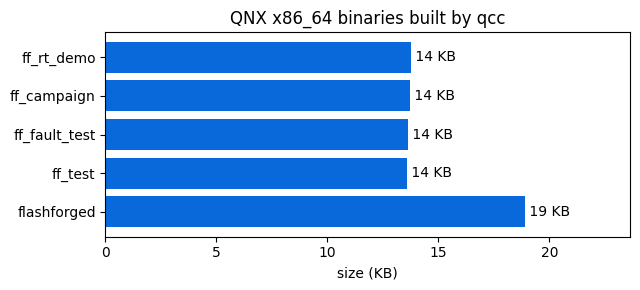

In [15]:
# Step 3 - Cross-compile for QNX (x86_64) with qcc and inspect the binaries
import struct
import matplotlib.pyplot as plt

p = Phase("03_build", "Build with qcc", "BUILD OK - QNX x86_64 BINARIES READY", "BUILD FAILED")
rc, out = sh(f"source '{SDP_ENV}' && cd '{PROJECT}' && rm -rf build && sh build.sh 2>&1", 600)
(LOGS / "build.log").write_text(out)
warnings = len(re.findall(r"warning:", out))
p.add("qcc -Vgcc_ntox86_64 (all five programs)", "PASS" if rc == 0 else "FAIL",
      f"exit {rc}; {warnings} warning(s)" + ("" if rc == 0 else " - see compiler output below"))

def elf_info(path):
    b = Path(path).read_bytes()[:64]
    if len(b) < 20 or b[:4] != b"\x7fELF":
        return None
    return {"class": {1: "32-bit", 2: "64-bit"}.get(b[4], "?"),
            "machine": {0x3E: "x86-64", 0xB7: "AArch64", 0x03: "x86"}.get(struct.unpack("<H", b[18:20])[0], "other")}

sizes = {}
for name in ("flashforged", "ff_test", "ff_fault_test", "ff_campaign", "ff_rt_demo"):
    f = PROJECT / "build" / name
    if not f.is_file():
        p.add(f"build/{name}", "FAIL", "missing")
        continue
    info = elf_info(f)
    sizes[name] = f.stat().st_size / 1024
    good = bool(info) and info["machine"] == "x86-64" and info["class"] == "64-bit"
    p.add(f"build/{name}", "PASS" if good else "FAIL",
          f"{f.stat().st_size:,} bytes; ELF {info['class']} {info['machine']}" if info else "not an ELF file")
failed_build = not p.finish(stop=False)

if failed_build:
    display(HTML("<h4>Compiler output (last 60 lines)</h4><pre style='background:#f6f8fa;color:#24292f;padding:10px;"
                 "overflow-x:auto;font-size:12px'>" + html.escape("\n".join(out.splitlines()[-60:])) + "</pre>"))
    raise RuntimeError("Build failed. Copy the compiler output above and send it for a fix.")

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.barh(list(sizes), list(sizes.values()), color="#0969da")
for i, v in enumerate(sizes.values()):
    ax.text(v, i, f" {v:.0f} KB", va="center")
ax.set_xlabel("size (KB)"); ax.set_title("QNX x86_64 binaries built by qcc")
ax.set_xlim(0, max(sizes.values()) * 1.25)
plt.tight_layout(); fig.savefig(FIGS / "build_sizes.png", dpi=150); plt.show()


## Step 4: Run it inside QNX 8.0

**4a. QEMU.** An open-source machine emulator. If it is missing, the cell installs it.

**4b. Build the VM image.** `mkqnximage` creates a bootable QNX 8.0 image. We add our five programs through its *snippet* files:
- `system_files.custom` copies the programs into the image.
- `post_start.custom` appends lines to the startup script: start the driver, wait, run the four test programs, print `FFRUN-END`.

**4c. Boot and capture.** QEMU boots the image with no network. Everything runs automatically at startup and is printed on the **serial console**, which the notebook captures. If the machine has no KVM, QEMU emulates the CPU in software; the cell prints a heartbeat every 30 seconds.

In [16]:
# Step 4a - Make sure QEMU is installed (about 1 minute the first time in a session)
p = Phase("04a_qemu", "QEMU", "QEMU READY", "QEMU NOT AVAILABLE")
if not (shutil.which("qemu-system-x86_64") and shutil.which("qemu-img")):
    rc, out = sh("export DEBIAN_FRONTEND=noninteractive; apt-get update -qq && "
                 "apt-get install -y -qq qemu-system-x86 qemu-utils", 900)
    (LOGS / "apt_qemu.log").write_text(out)
    p.add("apt-get install qemu-system-x86 qemu-utils", "PASS" if rc == 0 else "FAIL",
          "installed" if rc == 0 else "exit %d: %s" % (rc, out[-200:]))
else:
    p.add("apt-get install", "INFO", "skipped - already installed")
rc, ver = sh("qemu-system-x86_64 --version | head -1")
p.add("qemu-system-x86_64", "PASS" if rc == 0 else "FAIL", ver.strip())
rc, ver = sh("qemu-img --version | head -1")
p.add("qemu-img", "PASS" if rc == 0 else "FAIL", ver.strip())
p.finish()


#,Check,Status,Detail
1,apt-get install qemu-system-x86 qemu-utils,✅ PASS,installed
2,qemu-system-x86_64,✅ PASS,QEMU emulator version 8.2.2 (Debian 1:8.2.2+ds-0ubuntu1.18)
3,qemu-img,✅ PASS,qemu-img version 8.2.2 (Debian 1:8.2.2+ds-0ubuntu1.18)


True

In [17]:
# Step 4b - Build a QNX 8.0 virtual machine image that already contains our two programs
# and starts them automatically at boot. No network or SSH is needed: results come back over
# the serial console, which this notebook captures.
p = Phase("04b_image", "QNX VM image (mkqnximage)", "IMAGE READY", "IMAGE BUILD FAILED")

def mk(args, timeout=1500):
    return sh(f"source '{SDP_ENV}' && cd '{IMG_DIR}' && mkqnximage {args} 2>&1", timeout)

def build_text():
    """Text of the generated *.build files (list of files that go into the image)."""
    return "\n".join(f.read_text(errors="ignore") for f in sorted((IMG_DIR / "output").rglob("*.build")))

def hook_text():
    """Text of every small generated file (startup scripts live outside the *.build files)."""
    chunks = []
    for f in sorted((IMG_DIR / "output").rglob("*")):
        if f.is_file() and f.stat().st_size < 2_000_000 and not f.name.startswith(("disk", "ifs")):
            chunks.append(f.read_text(errors="ignore"))
    return "\n".join(chunks)

def qemu_format(path):
    rc, info = sh(f"qemu-img info --output=json '{path}'")
    try:
        return json.loads(info[info.index("{"):]).get("format", "raw")
    except Exception:
        return "raw"

if IMG_DIR.exists():
    shutil.rmtree(IMG_DIR)
IMG_DIR.mkdir(parents=True)

rc, out = mk("--type=qemu --arch=x86_64 --graphics=no --ssh-ident=none --build")
(LOGS / "mkqnximage_pass1.log").write_text(out)
p.add("mkqnximage first build (stock image)", "PASS" if rc == 0 else "FAIL",
      "ok" if rc == 0 else f"exit {rc}: " + out[-300:])
if rc != 0:
    p.finish()

snips = IMG_DIR / "local" / "snippets"
BIN_DIR = "xbin" if "xbin/" in build_text() else "bin"
p.add("Snippet folder", "PASS" if snips.is_dir() else "FAIL",
      ", ".join(sorted(x.name for x in snips.iterdir())) if snips.is_dir() else "local/snippets not found")
p.add("Executable directory in this SDP", "INFO", f"/system/{BIN_DIR}")
if not snips.is_dir():
    p.finish()

with open(snips / "system_files.custom", "a") as f:
    f.write("\n")
    for prog in ("flashforged", "ff_test", "ff_fault_test", "ff_campaign", "ff_rt_demo"):
        f.write(f"[uid=0 gid=0 perms=0755] {BIN_DIR}/{prog}={PROJECT}/build/{prog}\n")

with open(snips / "post_start.custom", "a") as f:
    f.write("\n")
    f.write("echo FFRUN-BEGIN\n")
    f.write(f"/system/{BIN_DIR}/flashforged &\n")
    f.write("sleep 10\n")
    for prog in ("ff_test", "ff_fault_test", "ff_campaign", "ff_rt_demo"):
        f.write(f"/system/{BIN_DIR}/{prog}\n")
    f.write("echo FFRUN-END\n")

rc, out = mk("--build")
(LOGS / "mkqnximage_pass2.log").write_text(out)
hook = "FFRUN-BEGIN" in hook_text()
if rc == 0 and not hook:
    rc, out = mk("--clean --build")
    (LOGS / "mkqnximage_pass2_clean.log").write_text(out)
    hook = "FFRUN-BEGIN" in hook_text()
p.add("mkqnximage rebuild with our programs", "PASS" if rc == 0 else "FAIL",
      "ok" if rc == 0 else f"exit {rc}: " + out[-300:])
p.add("our five programs added to image", "PASS" if "ff_rt_demo" in build_text() else "FAIL",
      "found in the generated build file" if "ff_rt_demo" in build_text() else "not found in output/build/*.build")
p.add("Auto-run hook added to startup script", "PASS" if hook else "FAIL",
      "found in the generated startup files" if hook else
      "not found - snippet files present: " + ", ".join(sorted(x.name for x in snips.iterdir())))

OUT = IMG_DIR / "output"
files = sorted(f for f in OUT.rglob("*") if f.is_file() and f.suffix != ".build")
display(HTML("<h4>Files produced by mkqnximage</h4>" +
             html_table(["File", "Size (MB)"], [(str(f.relative_to(OUT)), f"{f.stat().st_size/1e6:.1f}") for f in files[:40]],
                        mono_cols=(0,))))

IFS_BIN = OUT / "ifs.bin" if (OUT / "ifs.bin").is_file() else next((f for f in files if f.name.startswith("ifs") and f.suffix == ".bin"), None)
p.add("Boot image (ifs.bin)", "PASS" if IFS_BIN else "FAIL", f"{IFS_BIN.stat().st_size/1e6:.1f} MB" if IFS_BIN else "not found")

DRIVES = []   # (label, path, qemu format); the vmdk file is a tiny descriptor, disk-qemu holds the data
if (OUT / "disk-qemu.vmdk").is_file():
    DRIVES.append(("vmdk descriptor", OUT / "disk-qemu.vmdk", qemu_format(OUT / "disk-qemu.vmdk")))
if (OUT / "disk-qemu").is_file() and (OUT / "disk-qemu").stat().st_size > 1_000_000:
    DRIVES.append(("raw disk image", OUT / "disk-qemu", "raw"))
p.add("Disk image(s)", "PASS" if DRIVES else "FAIL",
      "; ".join(f"{l}: {pth.name} ({fmt}, {pth.stat().st_size/1e6:.1f} MB)" for l, pth, fmt in DRIVES) or "none found")

qopt = OUT / "build" / "qemu_options"
if qopt.is_file():
    p.add("QEMU options chosen by mkqnximage", "INFO", " ".join(qopt.read_text(errors="ignore").split())[:380])
p.finish()


File,Size (MB)
build/20-resolv.conf,0.0
build/build.date,0.0
build/dhcpcd-run-hooks,0.0
build/disk.layout,0.0
build/expandfs.sh,0.0
build/generate_files,0.0
build/group,0.0
build/mount_fs.sh,0.0
build/passwd,0.0
build/post_startup.sh,0.0


#,Check,Status,Detail
1,mkqnximage first build (stock image),✅ PASS,ok
2,Snippet folder,✅ PASS,"data_files.custom, ifs_files.custom, ifs_start.custom, post_start.custom, profile.custom, system_files.custom"
3,Executable directory in this SDP,ℹ️ INFO,/system/bin
4,mkqnximage rebuild with our programs,✅ PASS,ok
5,our five programs added to image,✅ PASS,found in the generated build file
6,Auto-run hook added to startup script,✅ PASS,found in the generated startup files
7,Boot image (ifs.bin),✅ PASS,10.9 MB
8,Disk image(s),✅ PASS,"vmdk descriptor: disk-qemu.vmdk (vmdk, 0.0 MB); raw disk image: disk-qemu (raw, 154.4 MB)"
9,QEMU options chosen by mkqnximage,ℹ️ INFO,


True

In [18]:
# Step 4c - Boot QNX 8.0 in QEMU and capture the serial console (1-9 minutes, depending on KVM)
p = Phase("04c_boot", "Boot QNX in QEMU", "QNX BOOTED AND FLASHFORGE RAN INSIDE IT", "BOOT / RUN FAILED")
SERIAL_LOG = LOGS / "qemu_serial.log"
ANSI = re.compile(r"\x1b\[[0-9;?]*[A-Za-z]")
kvm = os.access("/dev/kvm", os.R_OK | os.W_OK)
cpu_variants = ([["-enable-kvm", "-cpu", "host"]] if kvm else []) + [["-cpu", "max"], ["-cpu", "qemu64"]]
BOOT_TIMEOUT = 300 if kvm else 900

def boot_once(drive_path, drive_fmt, cpu_flags, timeout):
    cmd = ["qemu-system-x86_64", "-nographic", "-m", "1024", "-smp", "2" if kvm else "1", *cpu_flags,
           "-kernel", str(IFS_BIN), "-drive", f"file={drive_path},if=ide,format={drive_fmt}",
           "-no-reboot", "-nic", "none"]
    proc = subprocess.Popen(cmd, stdin=subprocess.DEVNULL, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    fd = proc.stdout.fileno()
    buf, t0, last, done_at = b"", time.time(), time.time(), None
    try:
        while time.time() - t0 < timeout:
            ready, _, _ = select.select([fd], [], [], 2)
            if ready:
                chunk = os.read(fd, 65536)
                if not chunk:
                    break
                buf += chunk
                if done_at is None and b"FFRUN-END" in buf:
                    done_at = time.time()
            elif proc.poll() is not None:
                break
            if done_at and time.time() - done_at > 3:
                break
            if time.time() - last > 30:
                tail = ANSI.sub("", buf.decode("utf-8", "replace")).strip().splitlines()[-1:]
                print(f"[{int(time.time()-t0):>4}s] " + (tail[0][:100] if tail else "(no console output yet)"))
                last = time.time()
    finally:
        proc.terminate()
        try:
            proc.wait(10)
        except Exception:
            proc.kill()
    return cmd, ANSI.sub("", buf.decode("utf-8", "replace")).replace("\r", ""), time.time() - t0

plan = [(l, pth, fmt, flags) for l, pth, fmt in DRIVES for flags in cpu_variants[:2]]
attempts, text, cmd = [], "", []
for n, (dlabel, dpath, dfmt, flags) in enumerate(plan):
    tmo = BOOT_TIMEOUT if n == 0 else 240
    print(f"Attempt {n+1}/{len(plan)}: {dlabel}, CPU {' '.join(flags)} (timeout {tmo}s)")
    cmd, text, secs = boot_once(dpath, dfmt, flags, tmo)
    ran = "FFRUN-BEGIN" in text
    booted = bool(re.search(r"QNX|procnto|Welcome", text, re.I))
    attempts.append((dlabel, " ".join(flags), "yes" if booted else "no", "yes" if ran else "no", f"{secs:.0f} s", len(text.splitlines())))
    (LOGS / f"qemu_serial_attempt{len(attempts)}.log").write_text(text)
    if ran or booted:      # QNX is up: trying other flags will not change what the startup script does
        break
SERIAL_LOG.write_text(text)

display(HTML("<h4>Boot attempts</h4>" + html_table(
    ["Disk", "QEMU CPU flags", "QNX console seen", "FlashForge started", "Time", "Console lines"], attempts, mono_cols=(1,))))
p.add("QEMU command", "INFO", " ".join(cmd))
p.add("QNX console output received", "PASS" if attempts and attempts[-1][2] == "yes" else "FAIL",
      f"{attempts[-1][5]} lines" if attempts and attempts[-1][2] == "yes" else "nothing recognizable on the serial console")
p.add("FlashForge auto-run reached (FFRUN-BEGIN)", "PASS" if "FFRUN-BEGIN" in text else "FAIL",
      "startup hook executed inside QNX" if "FFRUN-BEGIN" in text else "startup hook did not run")
p.add("Test programs finished (FFRESULT)", "PASS" if "FFRESULT|" in text else "FAIL",
      re.search(r"FFRESULT\|(\w+)", text).group(0) if "FFRESULT|" in text else "no result line captured")
ok = p.finish(stop=False)
if not ok:
    display(HTML("<h4>Last 60 console lines</h4><pre style='background:#f6f8fa;color:#24292f;padding:10px;overflow-x:auto;"
                 "font-size:12px'>" + html.escape("\n".join(text.splitlines()[-60:])) + "</pre>"))
    raise RuntimeError("Boot or run failed. Copy the console lines above and send them for a fix.")


Attempt 1/4: vmdk descriptor, CPU -cpu max (timeout 900s)
[  30s] flashforged: /dev/spinor0 ready (1024 KiB, 4096-byte sectors, fault engine on, multithreaded)


Disk,QEMU CPU flags,QNX console seen,FlashForge started,Time,Console lines
vmdk descriptor,-cpu max,yes,yes,51 s,223


#,Check,Status,Detail
1,QEMU command,ℹ️ INFO,"qemu-system-x86_64 -nographic -m 1024 -smp 1 -cpu max -kernel /root/ff_qemu_image/output/ifs.bin -drive file=/root/ff_qemu_image/output/disk-qemu.vmdk,if=ide,format=vmdk -no-reboot -nic none"
2,QNX console output received,✅ PASS,223 lines
3,FlashForge auto-run reached (FFRUN-BEGIN),✅ PASS,startup hook executed inside QNX
4,Test programs finished (FFRESULT),✅ PASS,FFRESULT|PASS


## Step 5: Base device results
Parsed from the serial console of the QNX guest.

- **Test table:** each of the 15 checks with a plain-English description of what it proves.
- **Bit-level figure:** the bytes the QNX device returned after each operation, next to what the NOR rules predict. Dark = 1, light = 0.
- **Latency chart:** emulated-time numbers, so compare operations with each other, not with datasheets.

#,Test,What it proves,Result
1,open_device,the resource manager is registered at /dev/spinor0 and can be opened,✅ PASS
2,geometry_devctl,devctl(FF_DCMD_GEOMETRY) works across the QNX message-passing boundary,✅ PASS
3,geometry_values,"reports 1 MiB, 4096-byte sectors, 256-byte pages, 256 sectors",✅ PASS
4,erase_sector0,sector erase command is accepted,✅ PASS
5,erased_reads_FF,an erased sector reads back as 0xFF,✅ PASS
6,program_first,first page program is accepted,✅ PASS
7,program_second,second program over the same bytes is accepted,✅ PASS
8,nor_and_semantics,programming can only clear bits: 0xF0 then 0x3C leaves 0x30 (a bitwise AND),✅ PASS
9,ones_do_not_set_bits,writing 0xFF over programmed data changes nothing,✅ PASS
10,erase_restores_FF,erase command is accepted again,✅ PASS


Total,Sector,Page,Sectors
1024 KiB,4096 bytes,256 bytes,256


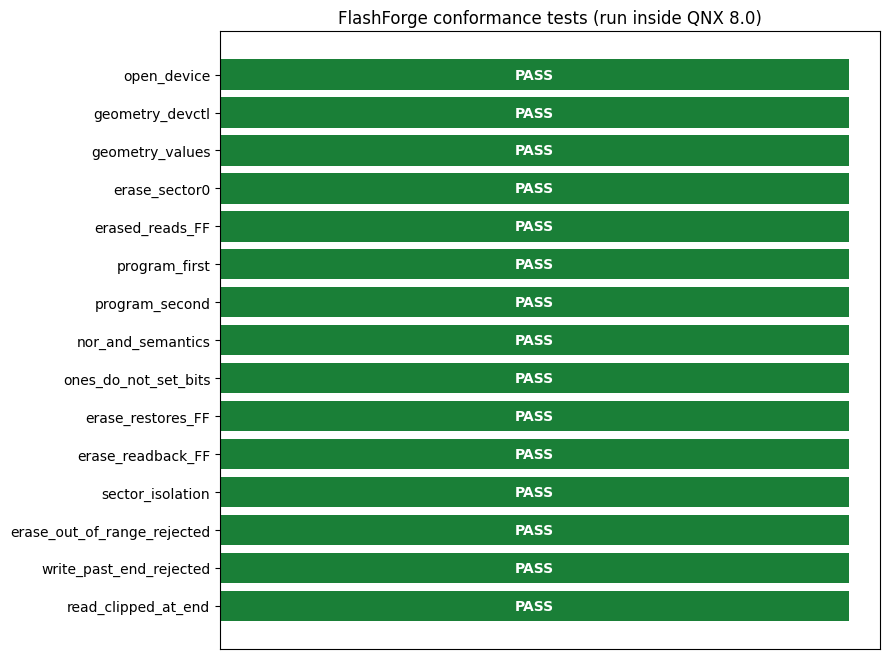

Step,Device (hex),Model (hex),Match
erased,FFFFFFFF,FFFFFFFF,✅ PASS
program1,F0FFAA55,F0FFAA55,✅ PASS
program2,300FAA50,300FAA50,✅ PASS
program_FF,300FAA50,300FAA50,✅ PASS
erased_again,FFFFFFFF,FFFFFFFF,✅ PASS


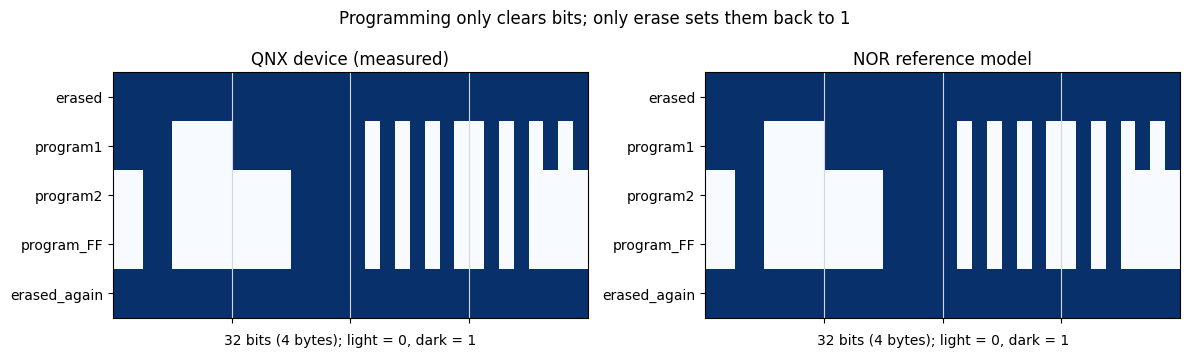

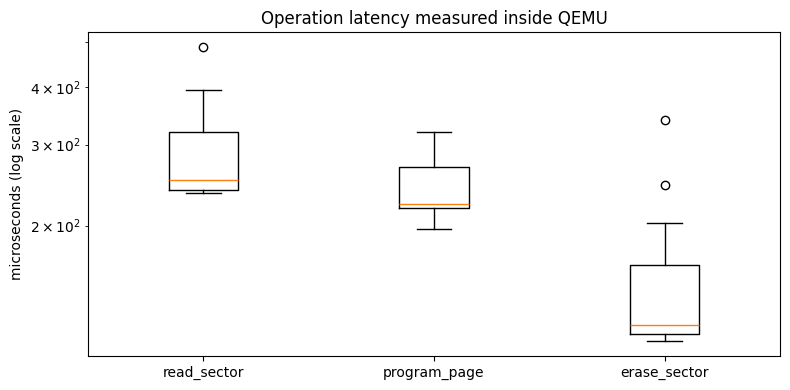

Operation,Samples,Min,Median,p95,Max
read_sector_us,20,234.9,251.6,399.8,488.7
program_page_us,16,196.4,223.3,303.7,320.0
erase_sector_us,20,112.0,121.7,250.2,339.6


1133

In [19]:
# Step 5 - Results: tables and charts built from what ran INSIDE QNX 8.0
import numpy as np
import matplotlib.pyplot as plt

raw = SERIAL_LOG.read_text(errors="replace") if SERIAL_LOG.exists() else ""
tests, bytes_seen, metrics, geom, final = [], {}, {}, None, None
for line in raw.splitlines():
    m = re.search(r"FF(TEST|BYTES|METRIC|GEOM|RESULT)\|(.*)$", line.strip())
    if not m:
        continue
    kind, rest = m.group(1), m.group(2).split("|")
    if kind == "TEST" and len(rest) >= 2:
        tests.append((rest[0], rest[1]))
    elif kind == "BYTES" and len(rest) >= 2:
        bytes_seen[rest[0]] = rest[1].strip()
    elif kind == "METRIC" and len(rest) >= 2:
        try:
            metrics.setdefault(rest[0], []).append(float(rest[1]))
        except ValueError:
            pass
    elif kind == "GEOM" and len(rest) >= 4:
        geom = rest[:4]
    elif kind == "RESULT":
        final = rest[0]

DESC = {
 "open_device": "the resource manager is registered at /dev/spinor0 and can be opened",
 "geometry_devctl": "devctl(FF_DCMD_GEOMETRY) works across the QNX message-passing boundary",
 "geometry_values": "reports 1 MiB, 4096-byte sectors, 256-byte pages, 256 sectors",
 "erase_sector0": "sector erase command is accepted",
 "erased_reads_FF": "an erased sector reads back as 0xFF",
 "program_first": "first page program is accepted",
 "program_second": "second program over the same bytes is accepted",
 "nor_and_semantics": "programming can only clear bits: 0xF0 then 0x3C leaves 0x30 (a bitwise AND)",
 "ones_do_not_set_bits": "writing 0xFF over programmed data changes nothing",
 "erase_restores_FF": "erase command is accepted again",
 "erase_readback_FF": "erase sets every bit back to 1",
 "sector_isolation": "erasing sector 0 does not disturb sector 1",
 "erase_out_of_range_rejected": "erasing a sector beyond the device is rejected",
 "write_past_end_rejected": "writing past the end of the device fails",
 "read_clipped_at_end": "reading across the end returns only the bytes that exist",
}
seen = dict(tests)
rows, n_pass = [], 0
for i, name in enumerate(DESC, 1):
    st = seen.get(name, "FAIL")
    n_pass += st == "PASS"
    rows.append((i, name, DESC[name], st if name in seen else "FAIL"))
banner(f"{n_pass} / {len(DESC)} tests passed inside QNX 8.0 (QEMU)", ok=(n_pass == len(DESC) and final == "PASS"),
       sub="Every number below was produced by code running on the QNX kernel, not on the notebook's Linux host.")
display(HTML(html_table(["#", "Test", "What it proves", "Result"], rows, status_col=3, mono_cols=(1,))))

if geom:
    display(HTML("<h4>Device geometry reported by the driver</h4>" + html_table(
        ["Total", "Sector", "Page", "Sectors"],
        [(f"{int(geom[0])//1024} KiB", f"{geom[1]} bytes", f"{geom[2]} bytes", geom[3])])))

# ---- Figure 1: test strip ----
fig, ax = plt.subplots(figsize=(9, 0.38 * len(DESC) + 1))
names = [r[1] for r in rows][::-1]
cols = ["#1a7f37" if r[3] == "PASS" else "#cf222e" for r in rows][::-1]
ax.barh(names, [1] * len(names), color=cols)
for i, c in enumerate(cols):
    ax.text(0.5, i, "PASS" if c == "#1a7f37" else "FAIL", ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks([]); ax.set_title("FlashForge conformance tests (run inside QNX 8.0)")
plt.tight_layout(); fig.savefig(FIGS / "tests.png", dpi=150); plt.show()

# ---- Reference NOR model: what the hardware rules say SHOULD happen ----
def nor_expected():
    state = [0xFF] * 4
    seq = [("erased", list(state))]
    for label, pat in (("program1", [0xF0, 0xFF, 0xAA, 0x55]), ("program2", [0x3C, 0x0F, 0xFF, 0xF0]),
                       ("program_FF", [0xFF] * 4)):
        state = [s & b for s, b in zip(state, pat)]
        seq.append((label, list(state)))
    seq.append(("erased_again", [0xFF] * 4))
    return seq

def bits(vals):
    return [(v >> (7 - k)) & 1 for v in vals for k in range(8)]

expected = nor_expected()
labels = [l for l, _ in expected]
model_m = np.array([bits(v) for _, v in expected])
dev_m = np.array([bits(list(bytes.fromhex(bytes_seen[l]))) if l in bytes_seen else [0] * 32 for l in labels])
matches = [(l, bytes_seen.get(l, "missing"), "".join(f"{x:02X}" for x in v),
            "PASS" if bytes_seen.get(l, "").upper() == "".join(f"{x:02X}" for x in v) else "FAIL") for l, v in expected]
display(HTML("<h4>Device bytes vs. the NOR reference model</h4>" +
             html_table(["Step", "Device (hex)", "Model (hex)", "Match"], matches, status_col=3, mono_cols=(1, 2))))

# ---- Figure 2: bit-level view ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, mat, title in ((axes[0], dev_m, "QNX device (measured)"), (axes[1], model_m, "NOR reference model")):
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xticks([x - 0.5 for x in range(8, 32, 8)]); ax.set_xticklabels([])
    ax.grid(axis="x", color="#d0d7de"); ax.set_xlabel("32 bits (4 bytes); light = 0, dark = 1"); ax.set_title(title)
plt.suptitle("Programming only clears bits; only erase sets them back to 1")
plt.tight_layout(); fig.savefig(FIGS / "bits.png", dpi=150); plt.show()

# ---- Figure 3: latency ----
if metrics:
    order = [k for k in ("read_sector_us", "program_page_us", "erase_sector_us") if k in metrics]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot([metrics[k] for k in order], showfliers=True)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels([k.replace("_us", "") for k in order])
    ax.set_yscale("log"); ax.set_ylabel("microseconds (log scale)")
    ax.set_title("Operation latency measured inside QEMU")
    plt.tight_layout(); fig.savefig(FIGS / "latency.png", dpi=150); plt.show()
    stat = []
    for k in order:
        a = np.array(metrics[k])
        stat.append((k, len(a), f"{a.min():.1f}", f"{np.median(a):.1f}", f"{np.percentile(a, 95):.1f}", f"{a.max():.1f}"))
    display(HTML("<h4>Latency statistics (microseconds)</h4>" + html_table(
        ["Operation", "Samples", "Min", "Median", "p95", "Max"], stat, mono_cols=(2, 3, 4, 5))))
    display(HTML("<p style='font-family:sans-serif;font-size:13px;color:#57606a'>QEMU runs on emulated time, so compare "
                 "operations with each other rather than reading these as hardware numbers. The next version of the driver "
                 "simulates real NOR timing (erase takes milliseconds) with QNX timers, so a high-priority thread keeps "
                 "its deadline while another thread is erasing.</p>"))
else:
    print("No timing data was captured.")

(RESULTS / "results.json").write_text(json.dumps({
    "tests_passed": n_pass, "tests_total": len(DESC), "final": final, "geometry": geom,
    "bytes": bytes_seen, "metrics": {k: v for k, v in metrics.items()}}, indent=2))


## Step 6: Do the fault commands work?
The 16 tests from `ff_fault_test.c`. Every fault used by the campaign in the next step is proven here first.

#,Test,What it proves,Result
1,reset_all_erases_and_zeroes_counters,"RESET_ALL returns the chip to factory-fresh: every byte 0xFF, counters at zero",✅ PASS
2,stats_count_erase_and_page_programs,counters see 1 erase and 2 page programs for a 300-byte write (a write is split per page),✅ PASS
3,op_before_cut_completes,operations before the armed power cut finish normally,✅ PASS
4,cut_op_fails,the operation that hits the power cut fails,✅ PASS
5,stats_report_torn_program,the driver reports the torn program and the power-off state,✅ PASS
6,writes_fail_while_power_is_off,no write succeeds while the chip has no power,✅ PASS
7,reads_fail_while_power_is_off,no read succeeds while the chip has no power,✅ PASS
8,power_restore_keeps_completed_data,"after power returns, data written before the cut is intact",✅ PASS
9,tear_is_deterministic_for_a_seed,the same seed tears a write the same way every time (bugs are reproducible),✅ PASS
10,tear_pattern_varies_with_seed,different seeds tear writes differently (so a campaign covers many outcomes),✅ PASS


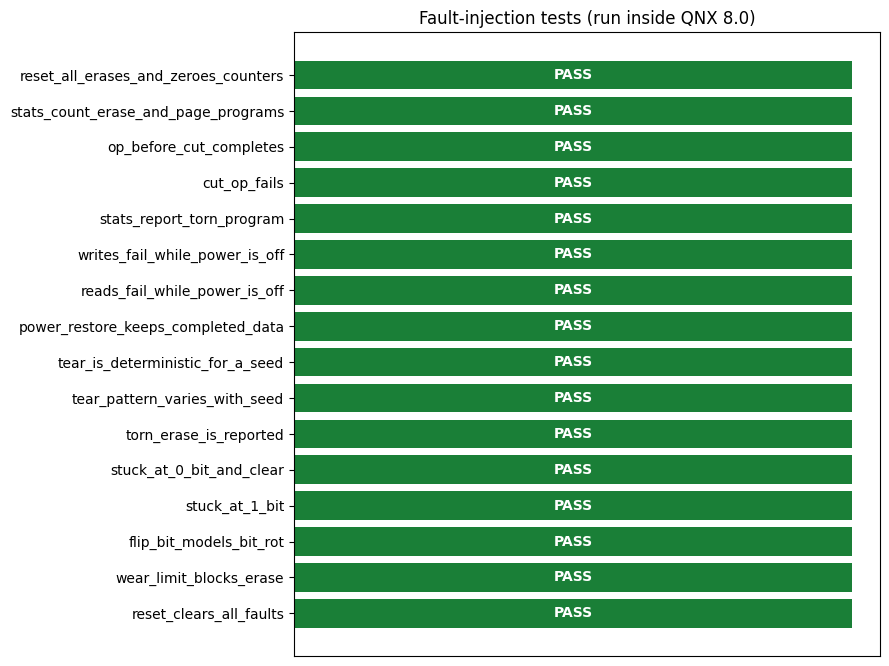

In [20]:
# Step 6 - Fault-injection tests: does every fault command really work?
import numpy as np
import matplotlib.pyplot as plt

raw = SERIAL_LOG.read_text(errors="replace") if SERIAL_LOG.exists() else ""
ft, ft_final = [], None
for line in raw.splitlines():
    m = re.search(r"FF(FTRESULT|FT)\|(.*)$", line.strip())
    if not m:
        continue
    parts = m.group(2).split("|")
    if m.group(1) == "FT" and len(parts) >= 2:
        ft.append((parts[0], parts[1]))
    elif m.group(1) == "FTRESULT":
        ft_final = parts[0]

FT_DESC = {
 "reset_all_erases_and_zeroes_counters": "RESET_ALL returns the chip to factory-fresh: every byte 0xFF, counters at zero",
 "stats_count_erase_and_page_programs": "counters see 1 erase and 2 page programs for a 300-byte write (a write is split per page)",
 "op_before_cut_completes": "operations before the armed power cut finish normally",
 "cut_op_fails": "the operation that hits the power cut fails",
 "stats_report_torn_program": "the driver reports the torn program and the power-off state",
 "writes_fail_while_power_is_off": "no write succeeds while the chip has no power",
 "reads_fail_while_power_is_off": "no read succeeds while the chip has no power",
 "power_restore_keeps_completed_data": "after power returns, data written before the cut is intact",
 "tear_is_deterministic_for_a_seed": "the same seed tears a write the same way every time (bugs are reproducible)",
 "tear_pattern_varies_with_seed": "different seeds tear writes differently (so a campaign covers many outcomes)",
 "torn_erase_is_reported": "a power cut during a sector erase is detected and reported",
 "stuck_at_0_bit_and_clear": "a bit stuck at 0 reads wrong until the fault is cleared",
 "stuck_at_1_bit": "a bit stuck at 1 reads wrong even on programmed data",
 "flip_bit_models_bit_rot": "a single stored bit can be flipped to model bit rot",
 "wear_limit_blocks_erase": "a sector stops erasing once it reaches its wear limit",
 "reset_clears_all_faults": "RESET_ALL also clears stuck bits and wear limits",
}
seen = dict(ft)
rows, n_pass = [], 0
for i, name in enumerate(FT_DESC, 1):
    st = seen.get(name, "FAIL")
    n_pass += st == "PASS"
    rows.append((i, name, FT_DESC[name], st))
all_ft_ok = n_pass == len(FT_DESC) and ft_final == "PASS"
banner(f"{n_pass} / {len(FT_DESC)} fault-injection tests passed inside QNX 8.0", ok=all_ft_ok,
       sub="Power cuts, torn writes, stuck bits, bit rot and wear-out are all controlled through devctl.")
display(HTML(html_table(["#", "Test", "What it proves", "Result"], rows, status_col=3, mono_cols=(1,))))

fig, ax = plt.subplots(figsize=(9, 0.36 * len(rows) + 1))
ax.barh([r[1] for r in rows][::-1], [1] * len(rows),
        color=["#1a7f37" if r[3] == "PASS" else "#cf222e" for r in rows][::-1])
for i, r in enumerate(rows[::-1]):
    ax.text(0.5, i, r[3], ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks([]); ax.set_title("Fault-injection tests (run inside QNX 8.0)")
plt.tight_layout(); fig.savefig(FIGS / "fault_tests.png", dpi=150); plt.show()

SCORE["06_fault_tests"] = {"title": "Fault-injection tests", "status": "PASS" if all_ft_ok else "FAIL",
                           "checks": [{"check": r[1], "status": r[3], "detail": ""} for r in rows]}


## Step 7: The power-cut campaign
This is the main result. Read the charts like this:

- **Verdict table:** how many of the experiments each design survived.
- **First failure table:** the smallest reproducer for each bug: *which* write the power was cut at and *which* tear pattern. Replaying that seed reproduces the corruption every time.
- **Outcome map:** one cell per experiment. Columns are cut points, rows are tear patterns. A column of green means the design recovered no matter how that write was torn.
- **Torn-write anatomy:** the 32-byte record being written when the power failed, bit by bit. The red bits are the damage the design has to cope with.

Design B is the interesting one. It checks a CRC, so it never accepts the half-written record, and recovery looks perfect. The bug appears one step later, when it writes a new record on top of the damaged slot: programming can only clear bits, so the new record can never become valid and acknowledged data is silently lost.

Design,Experiments,OK,Lost acknowledged data,Corrupt data accepted,Survived,Verdict
A: naive (no integrity check),385,3,0,382,0.8%,UNSAFE
"B: CRC, reuses torn slot",385,53,332,0,13.8%,UNSAFE
"C: CRC, skips torn slots",385,385,0,0,100.0%,SAFE


Design,Power cut,Tear,Class,When,Torn operation,What went wrong
A,cut at write #1,tear pattern 1,CORRUPT_ACCEPTED,phase 1,page program at flash offset 0,a recovered record does not match what was written
B,cut at write #1,tear pattern 1,LOST_ACKED,phase 2,page program at flash offset 0,acknowledged records are missing after recovery


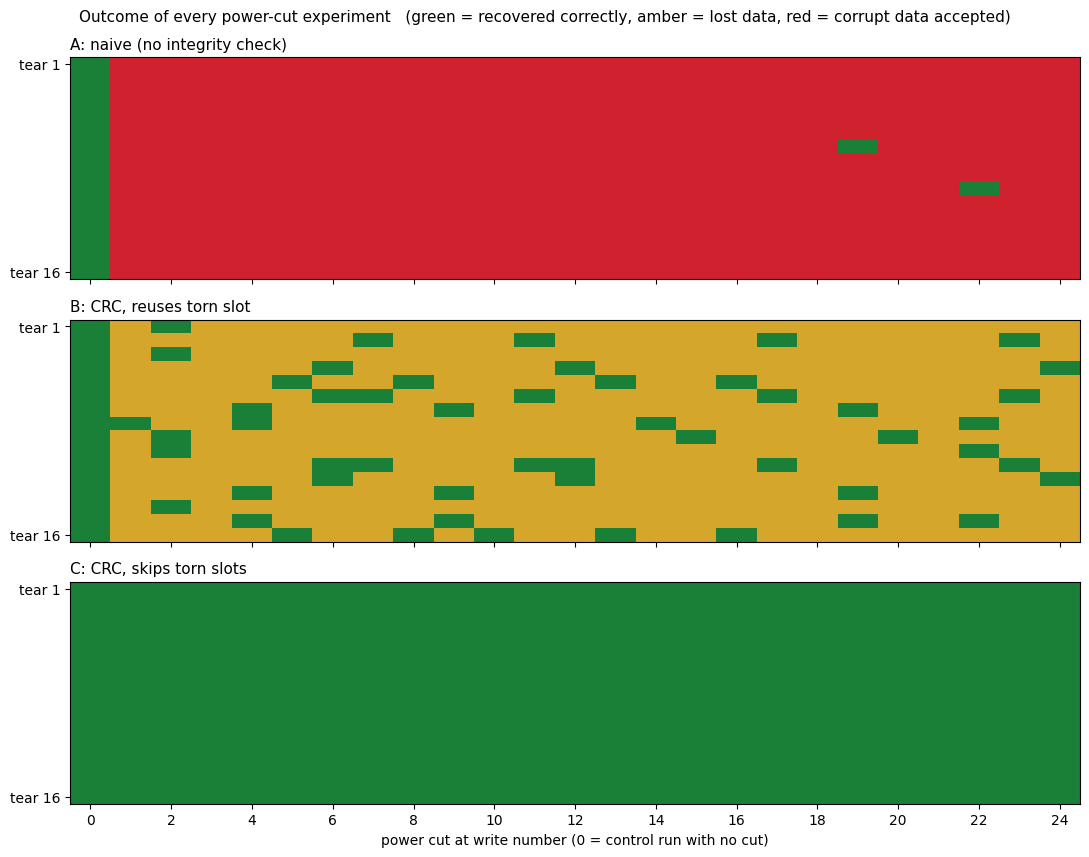

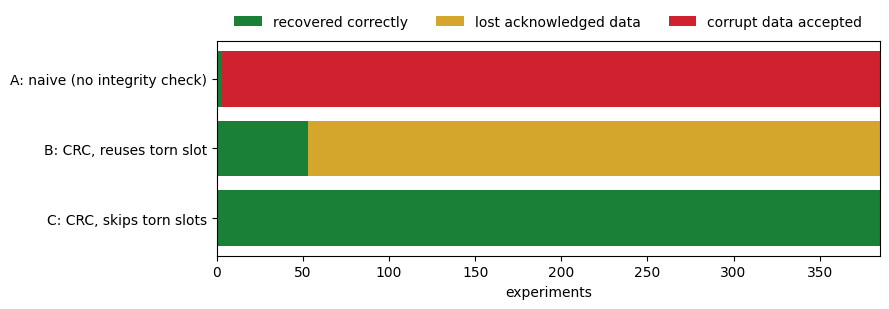

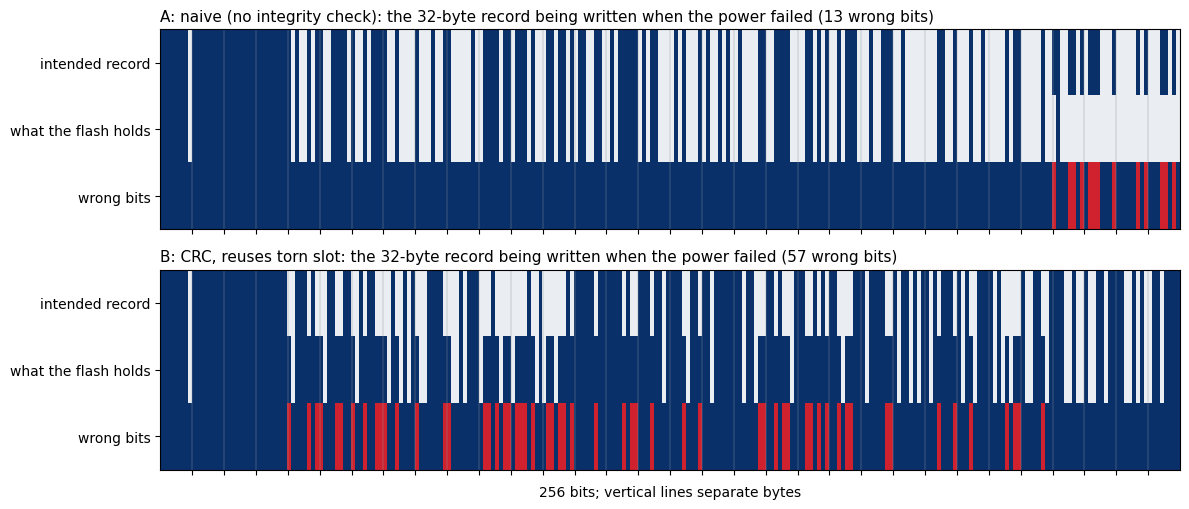

Design,Status,Detail
A,✅ PASS,"rows [385, 3, 0, 382] vs summary [385, 3, 0, 382]"
B,✅ PASS,"rows [385, 53, 332, 0] vs summary [385, 53, 332, 0]"
C,✅ PASS,"rows [385, 385, 0, 0] vs summary [385, 385, 0, 0]"


619

In [21]:
# Step 7 - The power-cut campaign: cut the power at every write, tear it 16 different ways, check recovery
from matplotlib.colors import ListedColormap

raw = SERIAL_LOG.read_text(errors="replace") if SERIAL_LOG.exists() else ""
cfg, design_text, grid_rows, sums, fails, torn, camp_final = None, {}, {}, {}, {}, {}, None
for line in raw.splitlines():
    m = re.search(r"FFCAMP(CFG|DESIGN|ROW|SUM|FAIL|TORN|RESULT)\|(.*)$", line.strip())
    if not m:
        continue
    kind, f = m.group(1), m.group(2).split("|")
    if kind == "CFG" and len(f) >= 4:
        cfg = [int(x) for x in f[:4]]
    elif kind == "DESIGN" and len(f) >= 2:
        design_text[f[0]] = "|".join(f[1:])
    elif kind == "ROW" and len(f) >= 3:
        grid_rows.setdefault(f[0], {})[int(f[1])] = f[2]
    elif kind == "SUM" and len(f) >= 5:
        sums[f[0]] = [int(x) for x in f[1:5]]
    elif kind == "FAIL" and len(f) >= 9:
        fails[f[0]] = f
    elif kind == "TORN" and len(f) >= 3:
        torn[f[0]] = (f[1], f[2])
    elif kind == "RESULT":
        camp_final = f[0]

if not (cfg and sums):
    raise RuntimeError("No campaign output found in the console log - did the boot step finish?")
NREC, NPOST, SEEDS, SLOT = cfg
names = sorted(sums)
NAMES = {"A": "A: naive (no integrity check)", "B": "B: CRC, reuses torn slot", "C": "C: CRC, skips torn slots"}
total_runs = sum(sums[d][0] for d in names)

c_clean = "C" in sums and sums["C"][2] + sums["C"][3] == 0
found = [d for d in names if d != "C" and sums[d][2] + sums[d][3] > 0]
banner(f"Campaign finished: {total_runs:,} power-cut experiments inside QNX 8.0",
       ok=(camp_final == "PASS"),
       sub=f"Bugs found in designs {', '.join(found) or 'none'}. Design C survived every power cut: {'yes' if c_clean else 'NO'}.")

# ---- table 1: verdict per design ----
rows = []
for d in names:
    runs, ok, lost, cor = sums[d]
    rows.append((NAMES.get(d, d), runs, ok, lost, cor, f"{100.0 * ok / runs:.1f}%",
                 "SAFE" if lost + cor == 0 else "UNSAFE"))
display(HTML("<h4>Verdict per store design</h4>" + html_table(
    ["Design", "Experiments", "OK", "Lost acknowledged data", "Corrupt data accepted", "Survived", "Verdict"], rows)))

# ---- table 2: first bug found in each unsafe design ----
bug_rows = []
for d in names:
    if d in fails:
        f = fails[d]
        kind = {"1": "page program", "2": "sector erase"}.get(f[6], "operation")
        bug_rows.append((d, f"cut at write #{f[1]}", f"tear pattern {f[2]}", f[3], f"phase {f[4]}",
                         f"{kind} at flash offset {f[7]}", f[8]))
if bug_rows:
    display(HTML("<h4>First failure found in each design (minimal reproducer: cut number + tear pattern)</h4>" + html_table(
        ["Design", "Power cut", "Tear", "Class", "When", "Torn operation", "What went wrong"], bug_rows)))

# ---- figure 1: outcome map ----
cmap = ListedColormap(["#1a7f37", "#d4a72c", "#cf222e"])
fig, axes = plt.subplots(len(names), 1, figsize=(11, 2.9 * len(names)), sharex=True)
axes = np.atleast_1d(axes)
for ax, d in zip(axes, names):
    mat = np.zeros((SEEDS, NREC + 1), dtype=int)
    for cut in range(NREC + 1):
        s = grid_rows.get(d, {}).get(cut, "0")
        for k in range(SEEDS):
            mat[k, cut] = int(s[k] if k < len(s) else s[0])
    ax.imshow(mat, cmap=cmap, vmin=0, vmax=2, aspect="auto", interpolation="nearest")
    ax.set_yticks([0, SEEDS - 1]); ax.set_yticklabels(["tear 1", f"tear {SEEDS}"])
    ax.set_title(NAMES.get(d, d), loc="left", fontsize=11)
    ax.set_xticks(range(0, NREC + 1, 2))
axes[-1].set_xlabel("power cut at write number (0 = control run with no cut)")
fig.suptitle("Outcome of every power-cut experiment   (green = recovered correctly, amber = lost data, red = corrupt data accepted)",
             fontsize=11)
plt.tight_layout(); fig.savefig(FIGS / "campaign_map.png", dpi=150); plt.show()

# ---- figure 2: totals ----
fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(names))
for idx, (label, color) in enumerate((("recovered correctly", "#1a7f37"), ("lost acknowledged data", "#d4a72c"),
                                      ("corrupt data accepted", "#cf222e"))):
    vals = np.array([sums[d][1 + idx] for d in names], dtype=float)
    ax.barh([NAMES.get(d, d) for d in names], vals, left=left, color=color, label=label)
    left += vals
ax.invert_yaxis(); ax.set_xlabel("experiments"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.tight_layout(); fig.savefig(FIGS / "campaign_totals.png", dpi=150); plt.show()

# ---- figure 3: anatomy of a torn write ----
def hex_bits(h):
    return np.array([(int(h[i:i + 2], 16) >> (7 - k)) & 1 for i in range(0, len(h), 2) for k in range(8)])

shown = [d for d in names if d in torn]
if shown:
    fig, axes = plt.subplots(len(shown), 1, figsize=(12, 2.6 * len(shown)))
    axes = np.atleast_1d(axes)
    for ax, d in zip(axes, shown):
        exp_b, act_b = hex_bits(torn[d][0]), hex_bits(torn[d][1])
        wrong = (exp_b != act_b).astype(int)
        ax.imshow(np.vstack([exp_b, act_b, wrong * 2]), cmap=ListedColormap(["#0a3069", "#eaeef2", "#cf222e"]),
                  vmin=0, vmax=2, aspect="auto", interpolation="nearest")
        ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["intended record", "what the flash holds", "wrong bits"])
        ax.set_xticks([x - 0.5 for x in range(8, SLOT * 8, 8)]); ax.set_xticklabels([])
        ax.grid(axis="x", color="#8c959f", linewidth=0.3)
        ax.set_title(f"{NAMES.get(d, d)}: the {SLOT}-byte record being written when the power failed "
                     f"({int(wrong.sum())} wrong bits)", loc="left", fontsize=11)
    axes[-1].set_xlabel(f"{SLOT * 8} bits; vertical lines separate bytes")
    plt.tight_layout(); fig.savefig(FIGS / "torn_write_anatomy.png", dpi=150); plt.show()

# ---- consistency check between the two ways the numbers were reported ----
chk = []
for d in names:
    s = "".join(grid_rows.get(d, {}).get(c, "") for c in range(NREC + 1))
    from_rows = [len(s), s.count("0"), s.count("1"), s.count("2")]
    chk.append((d, "PASS" if from_rows == sums[d] else "FAIL", f"rows {from_rows} vs summary {sums[d]}"))
display(HTML("<h4>Cross-check: per-experiment rows vs. the summary line</h4>" +
             html_table(["Design", "Status", "Detail"], chk, status_col=1, mono_cols=(2,))))

SCORE["07_campaign"] = {"title": "Power-cut campaign", "status": "PASS" if camp_final == "PASS" else "FAIL",
                        "checks": [{"check": NAMES.get(d, d), "status": "PASS" if (sums[d][2] + sums[d][3] == 0) == (d == "C") else "FAIL",
                                    "detail": f"{sums[d]}"} for d in names]}
(RESULTS / "campaign.json").write_text(json.dumps({"config": cfg, "summary": sums, "first_failures": fails}, indent=2))


## Step 8: Real-time demo
This answers the question *why QNX?* A real-time system is judged by its **worst case**, not its average. Read the results like this:

- **Table:** for each scenario, the median read, the 99th percentile, the worst read, and how many of the 400 reads missed their 5 ms deadline.
- **Latency over time:** every read, same scale in all three panels. The dashed blue line is the deadline.
- **Deadline curve:** what share of reads finishes within a given time. A curve that reaches 100% to the left of the dashed line means the deadline is always met.

What to expect: with the blocking erase, a read that arrives while the chip is erasing waits for the rest of the 45 ms, so almost every read misses its deadline. With erase-suspend, a read waits at most one 2 ms slice, and the background erases still finish at nearly the same rate.

> **Honest scope:** erase-suspend is a feature of real NOR chips, and here it is simulated with timers. The numbers come from QEMU, so absolute values are not hardware values, but the *comparison* between the scenarios is the point. The QNX contribution is the bounded, priority-correct behaviour: handlers run at the client's priority, the lock inherits priority, and the reader is a true `SCHED_FIFO` task.

Scenario,What runs,Median read,99th percentile,Worst read,Deadline misses,Erases finished,Deadline
idle,no erase running (floor),1.21 ms,1.51 ms,1.87 ms,0 of 400 (0%),0,MET
blocking,erase blocks the chip,22.62 ms,45.54 ms,45.63 ms,358 of 400 (90%),43,MISSED
suspend,erase suspends for reads,1.57 ms,1.79 ms,2.57 ms,0 of 400 (0%),30,MET


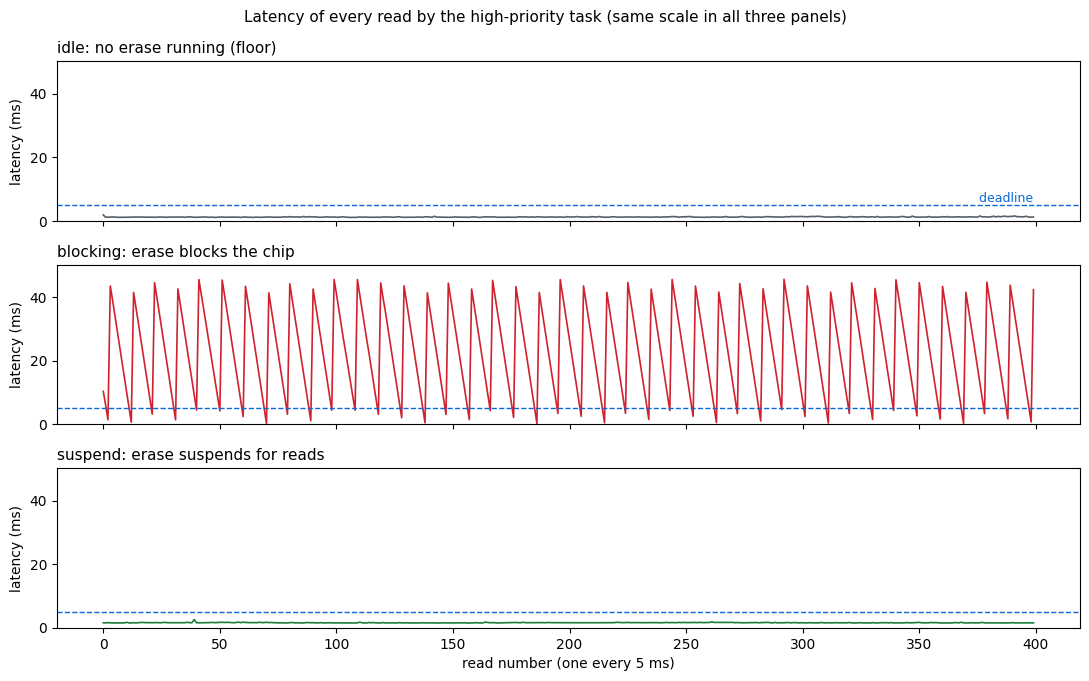

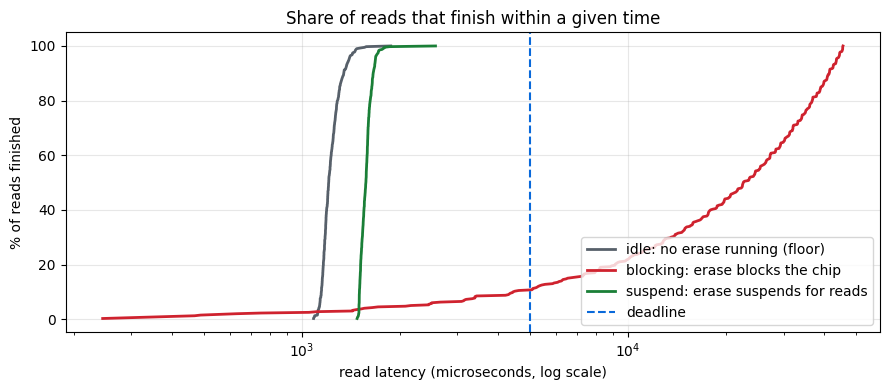

7808

In [22]:
# Step 8 - Real-time demo: does a high-priority reader keep its deadline while a slow erase is running?
import numpy as np
import matplotlib.pyplot as plt

raw = SERIAL_LOG.read_text(errors="replace") if SERIAL_LOG.exists() else ""
rt_cfg, rt_sum, rt_lat, rt_final, rt_peak, rt_threads = None, {}, {}, None, None, None
for line in raw.splitlines():
    m = re.search(r"FFRT(CFG|SUM|LAT|RESULT|INFO)\|(.*)$", line.strip())
    if not m:
        continue
    kind, f = m.group(1), m.group(2).split("|")
    if kind == "CFG" and len(f) >= 6:
        rt_cfg = [int(x) for x in f[:6]]
    elif kind == "SUM" and len(f) >= 8:
        rt_sum[f[0]] = [float(x) for x in f[1:8]]
    elif kind == "LAT" and len(f) >= 2:
        rt_lat[f[0]] = np.array([int(x) for x in f[1].split(",") if x.strip().isdigit()])
    elif kind == "INFO" and f[0].isdigit():
        rt_peak = int(f[0])
        rt_threads = int(f[1]) if len(f) > 1 and f[1].isdigit() else None
    elif kind == "RESULT":
        rt_final = f[0]
if not (rt_cfg and rt_sum):
    raise RuntimeError("No real-time demo output found in the console log - did the boot step finish?")

PERIOD, DEADLINE, ERASE, SLICE, NREADS, PRIO_OK = rt_cfg
LABEL = {"idle": "no erase running (floor)", "blocking": "erase blocks the chip", "suspend": "erase suspends for reads"}
order = [k for k in ("idle", "blocking", "suspend") if k in rt_sum]

rows = []
for k in order:
    n, p50, p99, worst, miss, erases, ms = rt_sum[k]
    rows.append((k, LABEL[k], f"{p50/1000:.2f} ms", f"{p99/1000:.2f} ms", f"{worst/1000:.2f} ms",
                 f"{int(miss)} of {int(n)} ({100*miss/n:.0f}%)", int(erases),
                 "MET" if miss == 0 else ("MOSTLY MET" if miss / n < 0.05 else "MISSED")))
blk, sus = rt_sum.get("blocking"), rt_sum.get("suspend")
headline = ""
if blk and sus:
    headline = (f"Blocking erase missed {int(blk[4])} of {int(blk[0])} deadlines; erase-suspend missed {int(sus[4])} "
                f"while still finishing {int(sus[5])} erases (vs {int(blk[5])}).")
banner("Real-time demo: " + ("a high-priority reader keeps its deadline" if rt_final == "PASS" else "result not as expected"),
       ok=(rt_final == "PASS"), sub=headline)
display(HTML(f"<p style='font-family:sans-serif;font-size:13px;color:#57606a'>A high-priority task reads the flash every {PERIOD/1000:.0f} ms and must "
             f"finish within {DEADLINE/1000:.0f} ms. A low-priority task erases sectors back to back; one erase takes {ERASE/1000:.0f} ms. "
             f"Real-time priorities set: {'yes' if PRIO_OK else 'NO (priority change was refused)'}. "
             f"Driver probe: most requests in flight at once = {rt_peak if rt_peak is not None else 'unknown'}, "
             f"different server threads used = {rt_threads if rt_threads is not None else 'unknown'} "
             f"({'requests are served concurrently' if (rt_peak or 0) >= 2 else 'a peak of 1 means the attribute lock is still serializing requests'}).</p>"))
display(HTML(html_table(["Scenario", "What runs", "Median read", "99th percentile", "Worst read", "Deadline misses",
                         "Erases finished", "Deadline"], rows, mono_cols=(2, 3, 4))))

# ---- figure 1: read latency over time ----
colors = {"idle": "#57606a", "blocking": "#cf222e", "suspend": "#1a7f37"}
ymax = max(float(rt_lat[k].max()) for k in order if k in rt_lat) / 1000 * 1.1
fig, axes = plt.subplots(len(order), 1, figsize=(11, 2.3 * len(order)), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, k in zip(axes, order):
    y = rt_lat[k] / 1000.0
    ax.plot(range(len(y)), y, color=colors[k], linewidth=1.2)
    ax.axhline(DEADLINE / 1000.0, color="#0969da", linestyle="--", linewidth=1)
    ax.set_ylim(0, ymax)
    ax.set_ylabel("latency (ms)")
    ax.set_title(f"{k}: {LABEL[k]}", loc="left", fontsize=11)
axes[0].text(len(rt_lat[order[0]]) - 1, DEADLINE / 1000.0, " deadline", color="#0969da", ha="right", va="bottom", fontsize=9)
axes[-1].set_xlabel(f"read number (one every {PERIOD/1000:.0f} ms)")
fig.suptitle("Latency of every read by the high-priority task (same scale in all three panels)", fontsize=11)
plt.tight_layout(); fig.savefig(FIGS / "realtime_latency.png", dpi=150); plt.show()

# ---- figure 2: how often is the deadline met? (cumulative distribution) ----
fig, ax = plt.subplots(figsize=(9, 4))
for k in order:
    v = np.sort(rt_lat[k]).astype(float)
    ax.plot(np.maximum(v, 1), 100.0 * np.arange(1, len(v) + 1) / len(v), color=colors[k], linewidth=2, label=f"{k}: {LABEL[k]}")
ax.axvline(DEADLINE, color="#0969da", linestyle="--", label="deadline")
ax.set_xscale("log"); ax.set_xlabel("read latency (microseconds, log scale)"); ax.set_ylabel("% of reads finished")
ax.set_title("Share of reads that finish within a given time"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); fig.savefig(FIGS / "realtime_cdf.png", dpi=150); plt.show()

SCORE["08_realtime"] = {"title": "Real-time demo", "status": "PASS" if rt_final == "PASS" else "FAIL",
                        "checks": [{"check": k, "status": "INFO", "detail": f"{rt_sum[k]}"} for k in order]}
(RESULTS / "realtime.json").write_text(json.dumps({"config": rt_cfg, "summary": rt_sum,
                                                   "latencies_us": {k: v.tolist() for k, v in rt_lat.items()}}))


## Step 9: Package
Collects the sources, figures and JSON into `flashforge_results.zip` and prints a scoreboard of all phases.

In [23]:
# Step 9 - Package everything: sources, logs, figures and JSON results in one zip
ZIP = Path("/kaggle/working/flashforge_results.zip")
if ZIP.exists():
    ZIP.unlink()
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(PROJECT.rglob("*")):
        if f.is_file() and "/build/" not in str(f) + "/" and f.name != "step1_sdp_install.log":
            z.write(f, f.relative_to(PROJECT.parent))
rows = [(v["title"], v["status"], len(v["checks"])) for v in SCORE.values()]
display(HTML("<h4>Scoreboard</h4>" + html_table(["Phase", "Status", "Checks"], rows, status_col=1)))
all_ok = all(r[1] == "PASS" for r in rows)
banner("FLASHFORGE RUN COMPLETE" if all_ok else "SOME PHASES FAILED", ok=all_ok,
       sub=f"Download {ZIP.name} from the notebook output (right-hand panel, /kaggle/working).")
print("Zip:", ZIP, f"({ZIP.stat().st_size/1024:.0f} KB)")


Phase,Status,Checks
Preflight,✅ PASS,8
QNX SDP 8.0,✅ PASS,7
Build with qcc,✅ PASS,6
QEMU,✅ PASS,3
QNX VM image (mkqnximage),✅ PASS,9
Boot QNX in QEMU,✅ PASS,4
Fault-injection tests,✅ PASS,16
Power-cut campaign,✅ PASS,3
Real-time demo,✅ PASS,3


Zip: /kaggle/working/flashforge_results.zip (661 KB)


## What comes next

| Feature | What it adds |
|---|---|
| Priority-inversion study | Add a medium-priority CPU-bound thread and show what happens to the reader with and without priority inheritance |
| A store with garbage collection | Two sectors, copy live records across, erase the old sector. Power cuts inside the copy and the erase are the hardest case |
| Wear and bit-rot campaigns | Run the same recovery checks with stuck bits, worn sectors and flipped bits |

## Troubleshooting

| Symptom | Fix |
|---|---|
| Preflight says Internet FAIL | Settings panel > Internet: On, then Run All |
| Preflight says installer FAIL | Add Input > Datasets > `qnx-software-center-installer` |
| Secrets WARN | Add-ons > Secrets: `QNX_USER`, `QNX_PASSWORD`, both ticked for this notebook |
| Install still says license problem | Add an optional secret `QNX_LICENSE_KEY` with your QNX 8.0 key, tick it for this notebook, re-run |
| Build fails | Copy the compiler output shown under the table and send it for a fix |
| Image or boot fails | Copy the red rows and the console lines shown under the table and send them for a fix |
| Session timed out | Run All again; nothing needs to be edited |

QNX is a trademark of BlackBerry Limited. This project is not affiliated with BlackBerry or QNX.
